# Ride Completion Prediction – NCR Ride Bookings

**Goal:** predict at booking time whether a ride will be completed, so high-risk bookings can be flagged early.

- **Target:** `Booking Status` → 1 = Completed, 0 = Not completed (customer or driver cancellation, no driver found, or incomplete ride).



In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import OneHotEncoder
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from imblearn.pipeline import Pipeline
from sklearn.base import BaseEstimator, TransformerMixin
from imblearn.over_sampling import SMOTE
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from lightgbm import LGBMClassifier
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, classification_report, confusion_matrix, ConfusionMatrixDisplay
from sklearn.metrics import roc_curve, roc_auc_score
from sklearn.model_selection import RandomizedSearchCV, TimeSeriesSplit
from sklearn.base import clone
from IPython.display import Markdown
import time



import warnings
warnings.filterwarnings('ignore')

pd.set_option('display.max_columns', None)



In [ ]:
# loading the dataset

df = pd.read_csv('/content/ncr_ride_bookings.csv')

print(f'Shape of dataset: {df.shape}')

Shape of dataset: (150000, 21)


In [ ]:
# checking null values

df.isnull().sum().to_frame('null values').reset_index()

,index,null values
0,Date,0
1,Time,0
2,Booking ID,0
3,Booking Status,0
4,Customer ID,0
5,Vehicle Type,0
6,Pickup Location,0
7,Drop Location,0
8,Avg VTAT,10500
9,Avg CTAT,48000


In [ ]:
# checking the data types

df.dtypes.to_frame('data types').reset_index()

,index,data types
0,Date,object
1,Time,object
2,Booking ID,object
3,Booking Status,object
4,Customer ID,object
5,Vehicle Type,object
6,Pickup Location,object
7,Drop Location,object
8,Avg VTAT,float64
9,Avg CTAT,float64


# Splitting the Data

In [ ]:
# encoding the target: 1 = Completed, 0 = Not completed
# (cancelled by customer or driver, no driver found, or incomplete ride)

booking_status_conditions = [
    df['Booking Status'] == 'Completed',
    df['Booking Status'] != 'Completed'
]

booking_status_choices = [1, 0]

df['Booking Status'] = np.select(booking_status_conditions, booking_status_choices, default = -1)

In [ ]:
# used for training and the latest 20% for testing (no shuffling)

split_idx = int(0.8 * len(df))
df.sort_values(by='Date', ascending=True, inplace=True)

train_df = df[:split_idx]
test_df = df[split_idx:]

print(f'Shape of training data: {train_df.shape}')
print(f'Shape of testing data: {test_df.shape}')

Shape of training data: (120000, 21)
Shape of testing data: (30000, 21)


In [ ]:
X_train = train_df.drop(columns=['Booking Status'])
y_train = train_df['Booking Status']

X_test = test_df.drop(columns=['Booking Status'])
y_test = test_df['Booking Status']

# EDA

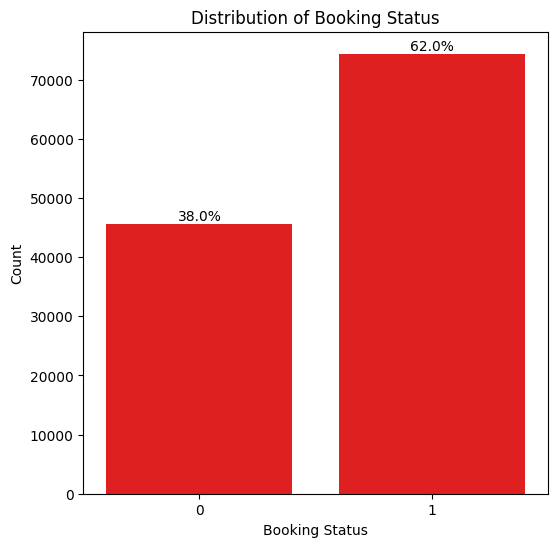

In [ ]:
plt.figure(figsize=(6,6))

ax = sns.countplot(data=train_df, x='Booking Status', color='red'
)

plt.title('Distribution of Booking Status')
plt.xlabel('Booking Status')
plt.ylabel('Count')

total = len(train_df)

for p in ax.patches:
    count = p.get_height()
    percentage = 100 * count / total
    ax.annotate(
        f'{percentage:.1f}%',
        (p.get_x() + p.get_width() / 2., count),
        ha='center',
        va='bottom'
    )

plt.show()


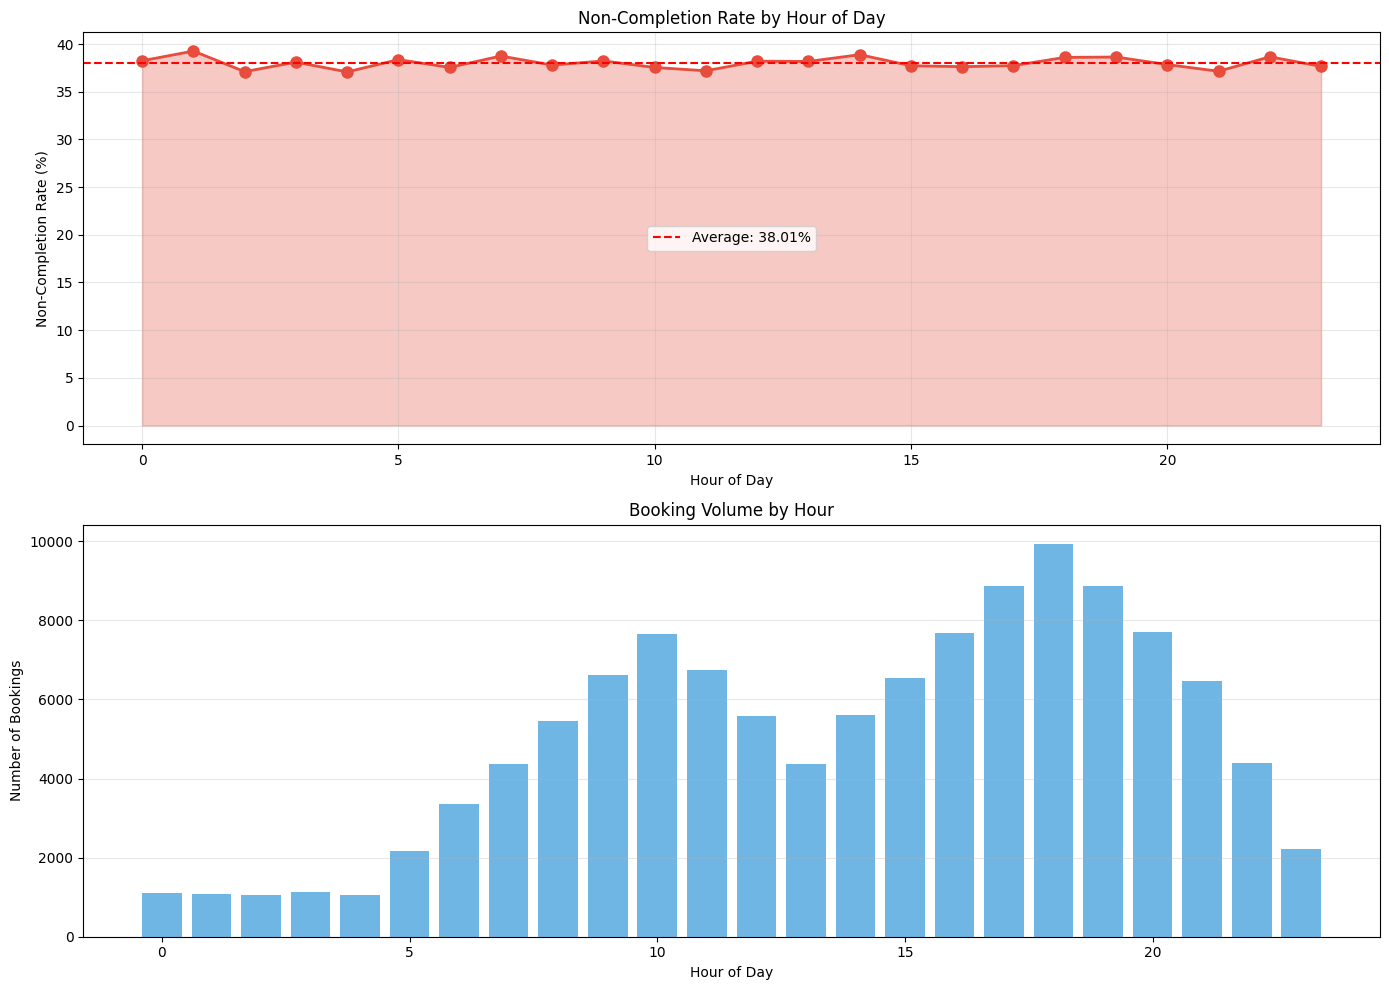

In [ ]:
train_df['DateTime'] = pd.to_datetime(train_df['Date'] + ' ' + train_df['Time'])
train_df['Hour'] = train_df['DateTime'].dt.hour
train_df['DayOfWeek'] = train_df['DateTime'].dt.dayofweek
train_df['DayName'] = train_df['DateTime'].dt.day_name()
train_df['IsWeekend'] = train_df['DayOfWeek'].isin([5, 6]).astype(int)

def get_time_slot(hour):
    if 6 <= hour < 10:
        return 'Morning Peak (6-10 AM)'
    elif 10 <= hour < 17:
        return 'Midday (10 AM-5 PM)'
    elif 17 <= hour < 21:
        return 'Evening Rush (5-9 PM)'
    else:
        return 'Night (9 PM-6 AM)'

train_df['TimeSlot'] = train_df['Hour'].apply(get_time_slot)


hourly_completion = train_df.groupby('Hour')['Booking Status'].agg(['mean', 'count']).reset_index()
hourly_completion['non_completion_rate'] = (1 - hourly_completion['mean']) * 100

fig, ax = plt.subplots(2, 1, figsize=(14, 10))

# Non-completion rate by hour
ax[0].plot(hourly_completion['Hour'], hourly_completion['non_completion_rate'],
           marker='o', linewidth=2, markersize=8, color='#e74c3c')
ax[0].fill_between(hourly_completion['Hour'], hourly_completion['non_completion_rate'],
                     alpha=0.3, color='#e74c3c')
ax[0].set_xlabel('Hour of Day')
ax[0].set_ylabel('Non-Completion Rate (%)')
ax[0].set_title('Non-Completion Rate by Hour of Day')
ax[0].axhline(y=hourly_completion['non_completion_rate'].mean(),
              color='red', linestyle='--',
              label=f'Average: {hourly_completion["non_completion_rate"].mean():.2f}%')
ax[0].legend()
ax[0].grid(True, alpha=0.3)

# Booking volume
ax[1].bar(hourly_completion['Hour'], hourly_completion['count'], color='#3498db', alpha=0.7)
ax[1].set_xlabel('Hour of Day')
ax[1].set_ylabel('Number of Bookings')
ax[1].set_title('Booking Volume by Hour')
ax[1].grid(True, alpha=0.3, axis='y')

plt.tight_layout()
plt.show()

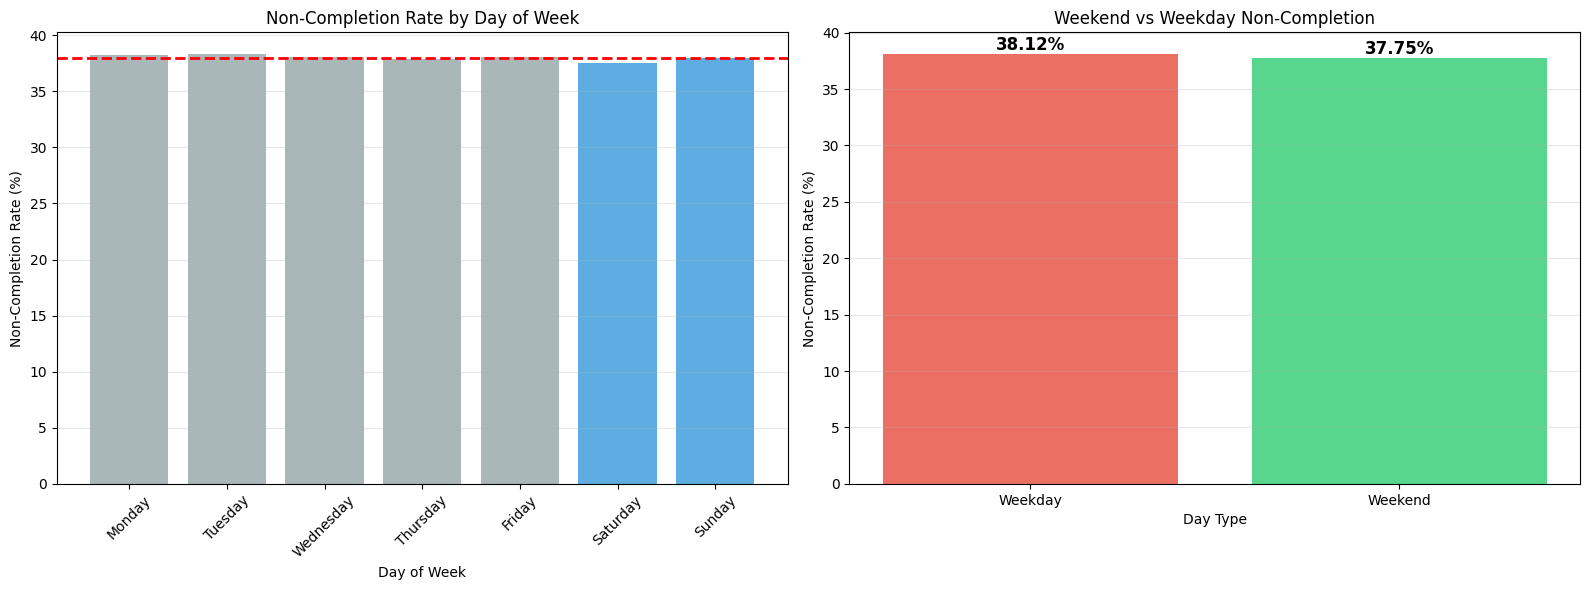

In [ ]:
day_order = ['Monday', 'Tuesday', 'Wednesday', 'Thursday', 'Friday', 'Saturday', 'Sunday']
daily_completion = train_df.groupby('DayName')['Booking Status'].agg(['mean', 'count']).reset_index()
daily_completion['non_completion_rate'] = (1 - daily_completion['mean']) * 100
daily_completion['DayName'] = pd.Categorical(daily_completion['DayName'],
                                              categories=day_order, ordered=True)
daily_completion = daily_completion.sort_values('DayName')

fig, ax = plt.subplots(1, 2, figsize=(16, 6))

# By day
ax[0].bar(daily_completion['DayName'], daily_completion['non_completion_rate'],
          color=['#3498db' if day in ['Saturday', 'Sunday'] else '#95a5a6'
                 for day in daily_completion['DayName']], alpha=0.8)
ax[0].set_xlabel('Day of Week')
ax[0].set_ylabel('Non-Completion Rate (%)')
ax[0].set_title('Non-Completion Rate by Day of Week')
ax[0].tick_params(axis='x', rotation=45)
ax[0].axhline(y=daily_completion['non_completion_rate'].mean(),
              color='red', linestyle='--', linewidth=2)
ax[0].grid(True, alpha=0.3, axis='y')

# Weekend vs Weekday
weekend_comparison = train_df.groupby('IsWeekend')['Booking Status'].agg(['mean', 'count']).reset_index()
weekend_comparison['non_completion_rate'] = (1 - weekend_comparison['mean']) * 100
weekend_comparison['Type'] = weekend_comparison['IsWeekend'].map({0: 'Weekday', 1: 'Weekend'})

bars = ax[1].bar(weekend_comparison['Type'], weekend_comparison['non_completion_rate'],
                 color=['#e74c3c', '#2ecc71'], alpha=0.8)
ax[1].set_xlabel('Day Type')
ax[1].set_ylabel('Non-Completion Rate (%)')
ax[1].set_title('Weekend vs Weekday Non-Completion')
ax[1].grid(True, alpha=0.3, axis='y')

for bar in bars:
    height = bar.get_height()
    ax[1].text(bar.get_x() + bar.get_width()/2., height,
               f'{height:.2f}%', ha='center', va='bottom', fontsize=12, fontweight='bold')

plt.tight_layout()
plt.show()

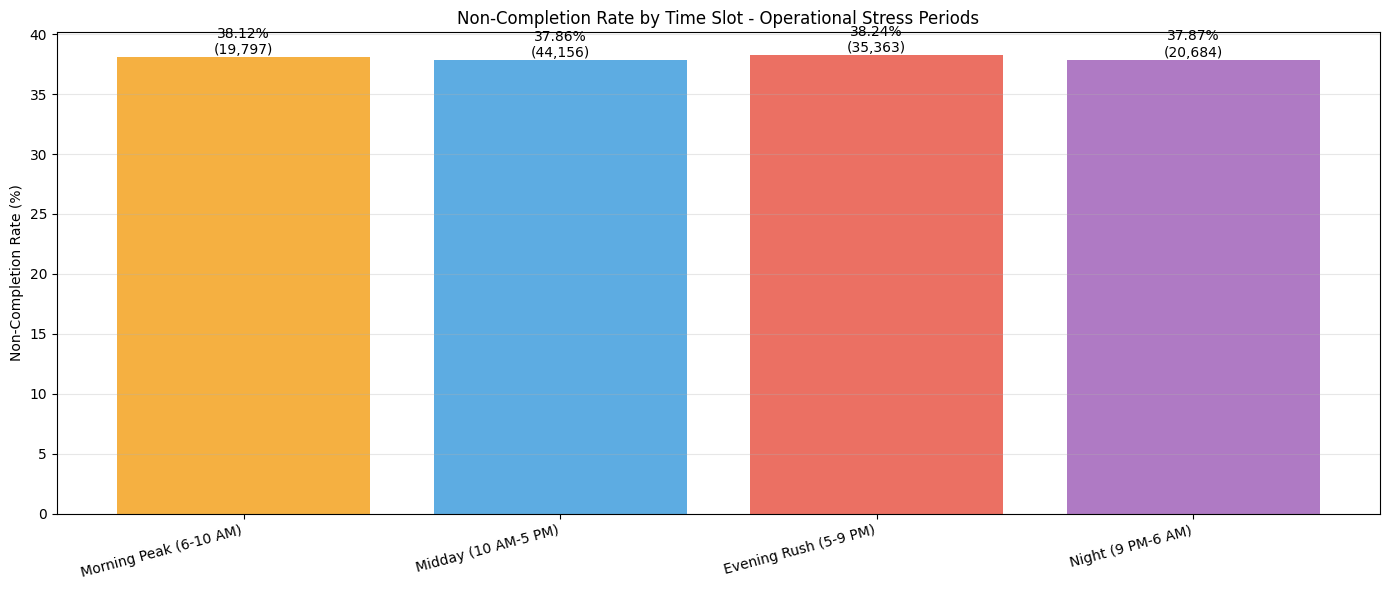

In [ ]:
timeslot_completion = train_df.groupby('TimeSlot')['Booking Status'].agg(['mean', 'count']).reset_index()
timeslot_completion['non_completion_rate'] = (1 - timeslot_completion['mean']) * 100

slot_order = ['Morning Peak (6-10 AM)', 'Midday (10 AM-5 PM)',
              'Evening Rush (5-9 PM)', 'Night (9 PM-6 AM)']
timeslot_completion['TimeSlot'] = pd.Categorical(timeslot_completion['TimeSlot'],
                                                  categories=slot_order, ordered=True)
timeslot_completion = timeslot_completion.sort_values('TimeSlot')

plt.figure(figsize=(14, 6))
bars = plt.bar(range(len(timeslot_completion)), timeslot_completion['non_completion_rate'],
               color=['#f39c12', '#3498db', '#e74c3c', '#9b59b6'], alpha=0.8)
plt.xticks(range(len(timeslot_completion)), timeslot_completion['TimeSlot'], rotation=15, ha='right')
plt.ylabel('Non-Completion Rate (%)')
plt.title('Non-Completion Rate by Time Slot - Operational Stress Periods')
plt.grid(True, alpha=0.3, axis='y')

for i, bar in enumerate(bars):
    height = bar.get_height()
    plt.text(bar.get_x() + bar.get_width()/2., height,
             f'{height:.2f}%\n({timeslot_completion.iloc[i]["count"]:,})',
             ha='center', va='bottom', fontsize=10)

plt.tight_layout()
plt.show()

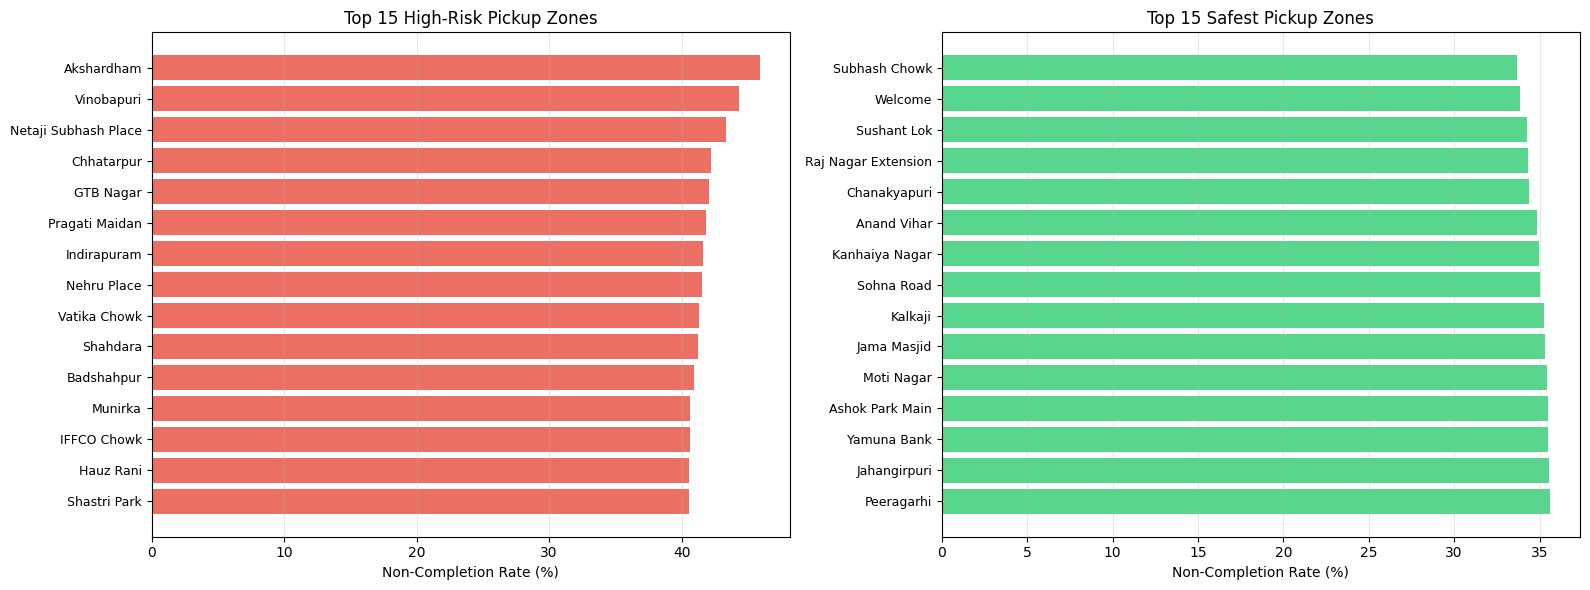

In [ ]:
pickup_stats = train_df.groupby('Pickup Location').agg({
    'Booking Status': ['mean', 'count']
}).reset_index()
pickup_stats.columns = ['Pickup Location', 'completion_rate', 'ride_count']
pickup_stats['non_completion_rate'] = (1 - pickup_stats['completion_rate']) * 100
pickup_stats = pickup_stats.sort_values('non_completion_rate', ascending=False)

# Top 15 riskiest zones
top_risk_pickup = pickup_stats.head(15)
safest_pickup = pickup_stats.tail(15).sort_values('non_completion_rate', ascending=True)

fig, ax = plt.subplots(1, 2, figsize=(16, 6))

# Risky zones
ax[0].barh(range(len(top_risk_pickup)), top_risk_pickup['non_completion_rate'],
           color='#e74c3c', alpha=0.8)
ax[0].set_yticks(range(len(top_risk_pickup)))
ax[0].set_yticklabels(top_risk_pickup['Pickup Location'], fontsize=9)
ax[0].set_xlabel('Non-Completion Rate (%)')
ax[0].set_title('Top 15 High-Risk Pickup Zones')
ax[0].invert_yaxis()
ax[0].grid(True, alpha=0.3, axis='x')

# Safest zones
ax[1].barh(range(len(safest_pickup)), safest_pickup['non_completion_rate'],
           color='#2ecc71', alpha=0.8)
ax[1].set_yticks(range(len(safest_pickup)))
ax[1].set_yticklabels(safest_pickup['Pickup Location'], fontsize=9)
ax[1].set_xlabel('Non-Completion Rate (%)')
ax[1].set_title('Top 15 Safest Pickup Zones')
ax[1].invert_yaxis()
ax[1].grid(True, alpha=0.3, axis='x')

plt.tight_layout()
plt.show()



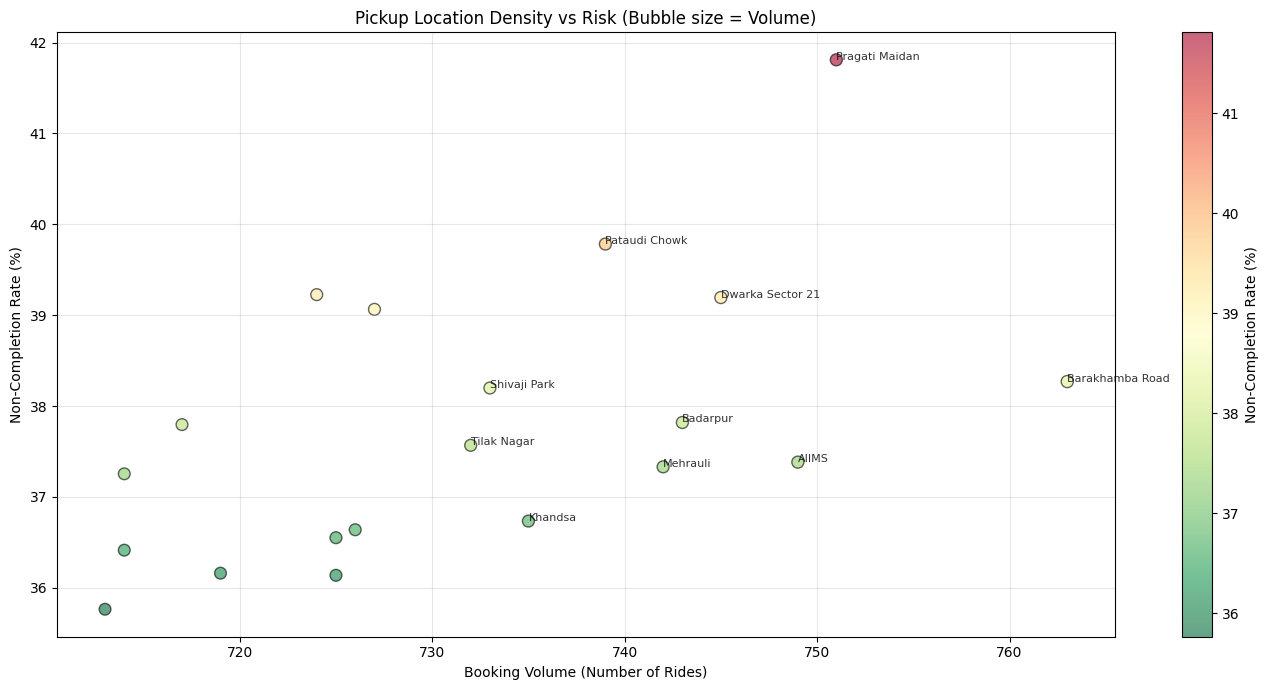

In [ ]:
pickup_density = train_df.groupby('Pickup Location').size().reset_index(name='booking_volume')
pickup_density = pickup_density.merge(pickup_stats[['Pickup Location', 'non_completion_rate']],
                                      on='Pickup Location')
pickup_density = pickup_density.sort_values('booking_volume', ascending=False).head(20)

plt.figure(figsize=(14, 7))
scatter = plt.scatter(pickup_density['booking_volume'],
                     pickup_density['non_completion_rate'],
                     s=pickup_density['booking_volume']/10,
                     c=pickup_density['non_completion_rate'],
                     cmap='RdYlGn_r', alpha=0.6, edgecolors='black', linewidth=1)

for _, row in pickup_density.head(10).iterrows():
    plt.annotate(row['Pickup Location'],
                (row['booking_volume'], row['non_completion_rate']),
                fontsize=8, alpha=0.8)

plt.xlabel('Booking Volume (Number of Rides)')
plt.ylabel('Non-Completion Rate (%)')
plt.title('Pickup Location Density vs Risk (Bubble size = Volume)')
plt.colorbar(scatter, label='Non-Completion Rate (%)')
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

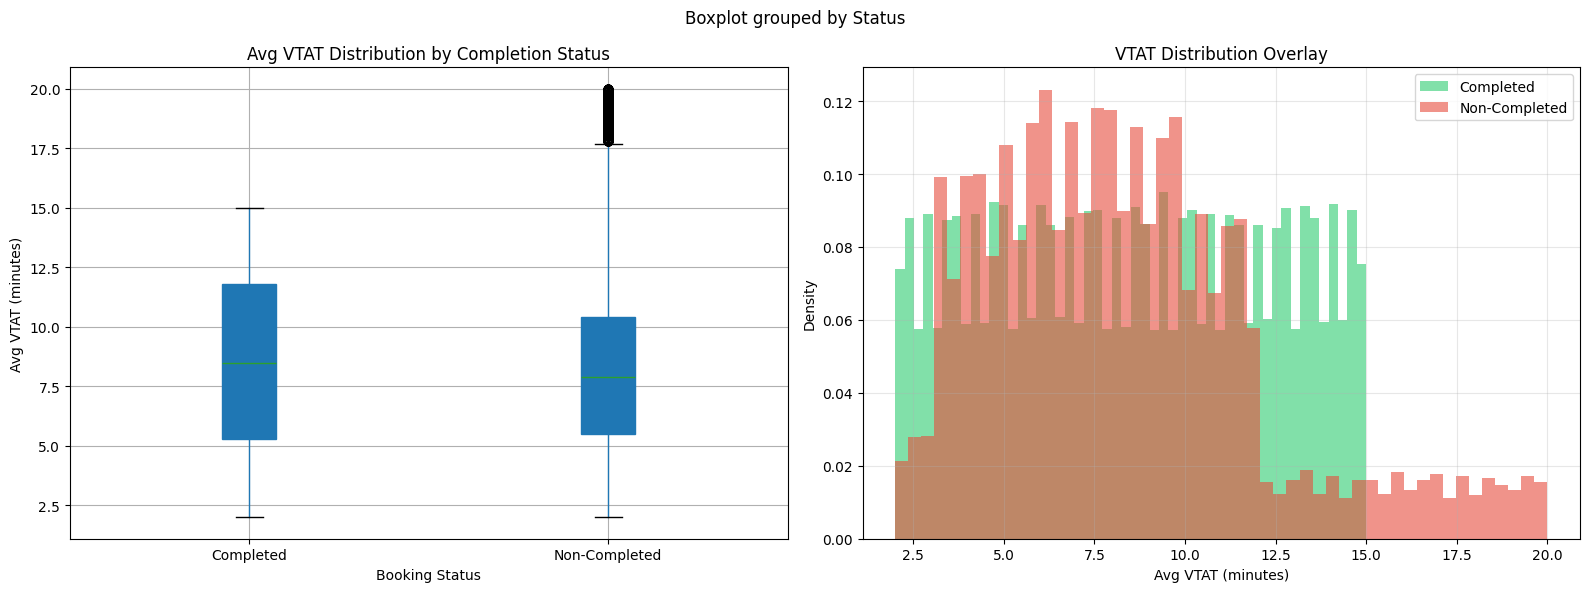

In [ ]:
df_vtat = train_df[train_df['Avg VTAT'].notna()].copy()
df_vtat['Status'] = df_vtat['Booking Status'].map({1: 'Completed', 0: 'Non-Completed'})

fig, ax = plt.subplots(1, 2, figsize=(16, 6))

# Box plot
df_vtat.boxplot(column='Avg VTAT', by='Status', ax=ax[0], patch_artist=True)
ax[0].set_title('Avg VTAT Distribution by Completion Status')
ax[0].set_xlabel('Booking Status')
ax[0].set_ylabel('Avg VTAT (minutes)')
plt.sca(ax[0])
plt.xticks(rotation=0)

# Histogram
completed_vtat = df_vtat[df_vtat['Booking Status']==1]['Avg VTAT']
non_completed_vtat = df_vtat[df_vtat['Booking Status']==0]['Avg VTAT']

ax[1].hist(completed_vtat, bins=50, alpha=0.6, label='Completed', color='#2ecc71', density=True)
ax[1].hist(non_completed_vtat, bins=50, alpha=0.6, label='Non-Completed', color='#e74c3c', density=True)
ax[1].set_xlabel('Avg VTAT (minutes)')
ax[1].set_ylabel('Density')
ax[1].set_title('VTAT Distribution Overlay')
ax[1].legend()
ax[1].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()


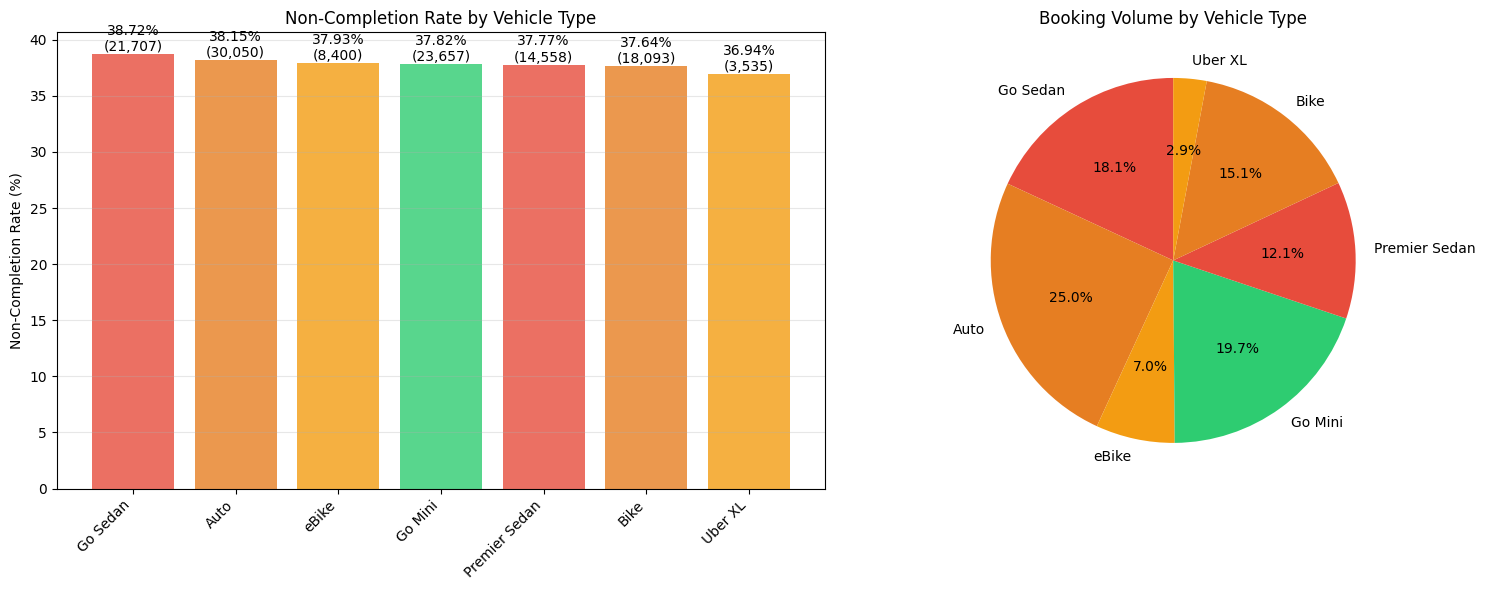

In [ ]:
vehicle_stats = train_df.groupby('Vehicle Type')['Booking Status'].agg(['mean', 'count']).reset_index()
vehicle_stats['non_completion_rate'] = (1 - vehicle_stats['mean']) * 100
vehicle_stats = vehicle_stats.sort_values('non_completion_rate', ascending=False)

fig, ax = plt.subplots(1, 2, figsize=(16, 6))

# Non-completion by vehicle
bars = ax[0].bar(range(len(vehicle_stats)), vehicle_stats['non_completion_rate'],
                 color=['#e74c3c', '#e67e22', '#f39c12', '#2ecc71'], alpha=0.8)
ax[0].set_xticks(range(len(vehicle_stats)))
ax[0].set_xticklabels(vehicle_stats['Vehicle Type'], rotation=45, ha='right')
ax[0].set_ylabel('Non-Completion Rate (%)')
ax[0].set_title('Non-Completion Rate by Vehicle Type')
ax[0].grid(True, alpha=0.3, axis='y')

for i, bar in enumerate(bars):
    height = bar.get_height()
    ax[0].text(bar.get_x() + bar.get_width()/2., height,
               f'{height:.2f}%\n({vehicle_stats.iloc[i]["count"]:,})',
               ha='center', va='bottom', fontsize=10)

# Volume distribution
ax[1].pie(vehicle_stats['count'], labels=vehicle_stats['Vehicle Type'], autopct='%1.1f%%',
          colors=['#e74c3c', '#e67e22', '#f39c12', '#2ecc71'], startangle=90)
ax[1].set_title('Booking Volume by Vehicle Type')

plt.tight_layout()
plt.show()

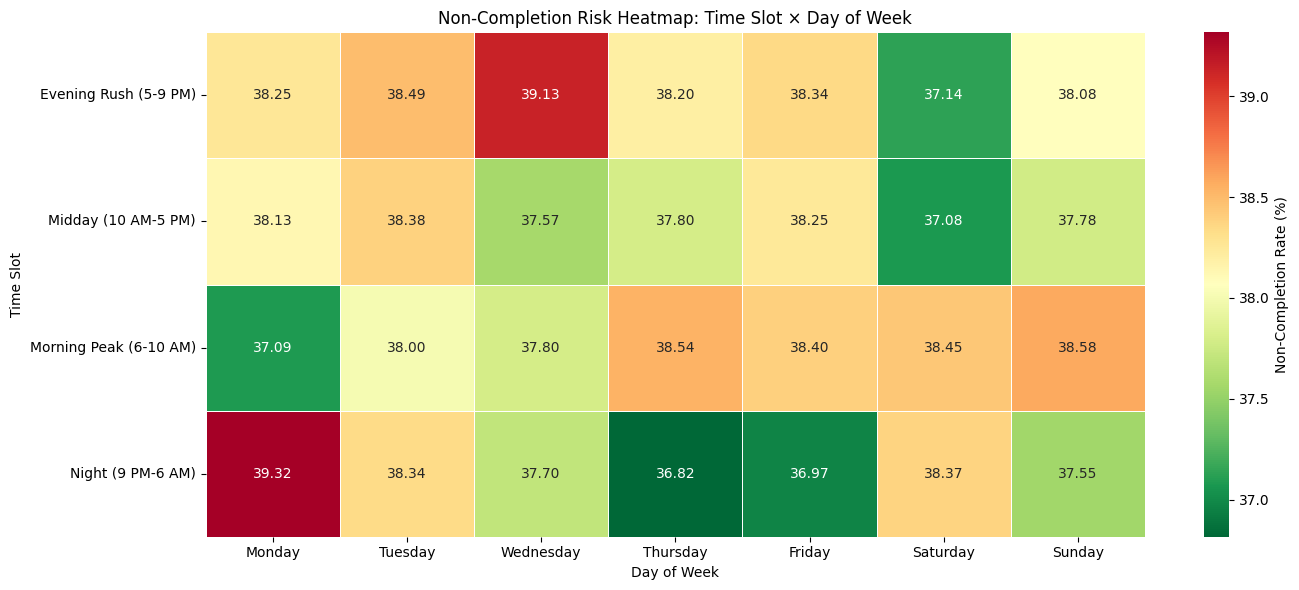

In [ ]:
time_day_heatmap = train_df.groupby(['TimeSlot', 'DayName'])['Booking Status'].mean().reset_index()
time_day_heatmap['non_completion_rate'] = (1 - time_day_heatmap['Booking Status']) * 100

pivot_time_day = time_day_heatmap.pivot(index='TimeSlot', columns='DayName',
                                         values='non_completion_rate')
pivot_time_day = pivot_time_day[day_order]

plt.figure(figsize=(14, 6))
sns.heatmap(pivot_time_day, annot=True, fmt='.2f', cmap='RdYlGn_r',
            cbar_kws={'label': 'Non-Completion Rate (%)'}, linewidths=0.5)
plt.title('Non-Completion Risk Heatmap: Time Slot × Day of Week')
plt.xlabel('Day of Week')
plt.ylabel('Time Slot')
plt.tight_layout()
plt.show()


# Data Cleaning and Engineering

In [ ]:
X_train_cleaned = X_train.copy()
X_test_cleaned = X_test.copy()

In [ ]:
# cleaning customer ID and booking ID

X_train_cleaned['Customer ID'] = X_train_cleaned['Customer ID'].str.strip('"')
X_train_cleaned['Booking ID'] = X_train_cleaned['Booking ID'].str.strip('"')

X_test_cleaned['Customer ID'] = X_test_cleaned['Customer ID'].str.strip('"')
X_test_cleaned['Booking ID'] = X_test_cleaned['Booking ID'].str.strip('"')

In [ ]:
leakage_features = ['Ride Distance', 'Booking Value', 'Driver Ratings', 'Customer Rating', 'Payment Method', 'Reason for cancelling by Customer','Driver Cancellation Reason',
                    'Incomplete Rides Reason']

X_train_cleaned.drop(columns = leakage_features, inplace=True)
X_test_cleaned.drop(columns = leakage_features, inplace=True)

In [ ]:
# time slot of day (model feature)
# (Morning 6-10, Midday 10-17, Evening 17-21, Night 21-6).

X_train_cleaned['Date'] = pd.to_datetime(X_train_cleaned['Date'], errors='coerce')
X_train_cleaned['Hour'] = pd.to_datetime(X_train_cleaned['Time'], format='%H:%M:%S', errors='coerce').dt.hour

X_test_cleaned['Date'] = pd.to_datetime(X_test_cleaned['Date'], errors='coerce')
X_test_cleaned['Hour'] = pd.to_datetime(X_test_cleaned['Time'], format='%H:%M:%S', errors='coerce').dt.hour

train_time_slot_conditions = [
    (X_train_cleaned['Hour'] >= 0) & (X_train_cleaned['Hour'] < 6),
    (X_train_cleaned['Hour'] >= 6) & (X_train_cleaned['Hour'] < 10),
    (X_train_cleaned['Hour'] >= 10) & (X_train_cleaned['Hour'] < 16),
    (X_train_cleaned['Hour'] >= 16) & (X_train_cleaned['Hour'] < 20),
    (X_train_cleaned['Hour'] >= 20) & (X_train_cleaned['Hour'] < 24)
]

test_time_slot_conditions = [
    (X_test_cleaned['Hour'] >= 0) & (X_test_cleaned['Hour'] < 6),
    (X_test_cleaned['Hour'] >= 6) & (X_test_cleaned['Hour'] < 10),
    (X_test_cleaned['Hour'] >= 10) & (X_test_cleaned['Hour'] < 16),
    (X_test_cleaned['Hour'] >= 16) & (X_test_cleaned['Hour'] < 20),
    (X_test_cleaned['Hour'] >= 20) & (X_test_cleaned['Hour'] < 24)
]

time_slot_choices = ['Late Night', 'Morning Peak', 'Midday', 'Evening Rush', 'Night']

X_train_cleaned['Time Slot of Day'] = np.select(train_time_slot_conditions, time_slot_choices, default = 'NA')
X_test_cleaned['Time Slot of Day'] = np.select(test_time_slot_conditions, time_slot_choices, default = 'NA')


In [ ]:
# extracting day of week
X_train_cleaned['Day of Week'] = X_train_cleaned['Date'].dt.day_name()
X_test_cleaned['Day of Week'] = X_test_cleaned['Date'].dt.day_name()

# creating a new column is weekend
X_train_cleaned['Is Weekend'] = np.where(X_train_cleaned['Day of Week'].isin(['Saturday', 'Sunday']), 1, 0)
X_test_cleaned['Is Weekend'] = np.where(X_test_cleaned['Day of Week'].isin(['Saturday', 'Sunday']), 1, 0)

In [ ]:
# pickup location density: number of training bookings per (pickup location, time slot),
# divided by the largest count so values fall between 0 and 1

pickup_location_count = X_train_cleaned.groupby(['Pickup Location', 'Time Slot of Day']).size().rename('Booking Density')
pickup_location_density = round(pickup_location_count/pickup_location_count.max(), 3) # min max normalisation forces some of them to be zero. Divide by max, low activity zone is still active

X_train_cleaned  = X_train_cleaned.merge(pickup_location_density, on=['Pickup Location', 'Time Slot of Day'], how='left')
X_test_cleaned  = X_test_cleaned.merge(pickup_location_density, on=['Pickup Location', 'Time Slot of Day'], how='left')

In [ ]:
# filling null values
X_train_cleaned['Cancelled Rides by Customer'].fillna(0, inplace = True)
X_test_cleaned['Cancelled Rides by Customer'].fillna(0, inplace = True)

X_train_cleaned['Cancelled Rides by Driver'].fillna(0, inplace = True)
X_test_cleaned['Cancelled Rides by Driver'].fillna(0, inplace = True)

X_train_cleaned['Incomplete Rides'].fillna(0, inplace = True)
X_test_cleaned['Incomplete Rides'].fillna(0, inplace = True)

X_train_cleaned['Avg VTAT'].fillna(X_train_cleaned['Avg VTAT'].mean().round(4), inplace = True)
X_test_cleaned['Avg VTAT'].fillna(X_train_cleaned['Avg VTAT'].mean().round(4), inplace = True)

X_train_cleaned['Avg CTAT'].fillna(X_train_cleaned['Avg CTAT'].mean().round(4), inplace = True)
X_test_cleaned['Avg CTAT'].fillna(X_train_cleaned['Avg CTAT'].mean().round(4), inplace = True)


In [ ]:
# customer non-completion rate (history feature)

_tr = X_train_cleaned[['Customer ID', 'Date', 'Time']].assign(_completed=y_train.values, _set='train', _pos=np.arange(len(X_train_cleaned)))
_te = X_test_cleaned[['Customer ID', 'Date', 'Time']].assign(_completed=y_test.values, _set='test', _pos=np.arange(len(X_test_cleaned)))

history = pd.concat([_tr, _te], ignore_index=True)
history['_ts'] = pd.to_datetime(history['Date'].astype(str).str[:10] + ' ' + history['Time'])
history = history.sort_values('_ts', kind='stable')

history['_cancelled'] = 1 - history['_completed']
history['_prior_rides'] = history.groupby('Customer ID').cumcount()
history['_prior_cancels'] = history.groupby('Customer ID')['_cancelled'].cumsum() - history['_cancelled']

# customers with no earlier rides get the overall training cancellation rate
overall_rate = 1 - y_train.mean()
history['Customer_Cancellation_Rate'] = np.where(
    history['_prior_rides'] > 0,
    history['_prior_cancels'] / history['_prior_rides'].clip(lower=1),
    overall_rate
)

X_train_cleaned['Customer_Cancellation_Rate'] = history[history['_set'] == 'train'].sort_values('_pos')['Customer_Cancellation_Rate'].values
X_test_cleaned['Customer_Cancellation_Rate'] = history[history['_set'] == 'test'].sort_values('_pos')['Customer_Cancellation_Rate'].values

In [ ]:
# estimated route distance and predicted trip duration
# Predicted Trip Duration: Estimated_Distance / Expected Speed, in minutes

completed_rides = train_df[train_df['Ride Distance'].notna()].copy()

route_distances = completed_rides.groupby(['Pickup Location', 'Drop Location'])['Ride Distance'].mean().reset_index()
route_distances.columns = ['Pickup Location', 'Drop Location', 'Estimated_Distance']

X_train_cleaned = X_train_cleaned.merge(route_distances, on=['Pickup Location', 'Drop Location'], how='left')
X_test_cleaned = X_test_cleaned.merge(route_distances, on=['Pickup Location', 'Drop Location'], how='left')

overall_avg_distance = completed_rides['Ride Distance'].mean()
X_train_cleaned['Estimated_Distance'].fillna(overall_avg_distance, inplace=True)
X_test_cleaned['Estimated_Distance'].fillna(overall_avg_distance, inplace=True)


base_speed = {  # assumed average speeds in km/h (not measured from the data)
    'Late Night': 35,
    'Morning Peak': 18,
    'Midday': 25,
    'Evening Rush': 16,
    'Night': 30
}

X_train_cleaned['Expected Speed'] = X_train_cleaned['Time Slot of Day'].map(base_speed) * (1 - 0.3 * X_train_cleaned['Booking Density'])
X_test_cleaned['Expected Speed'] = X_test_cleaned['Time Slot of Day'].map(base_speed) * (1 - 0.3 * X_test_cleaned['Booking Density'])

X_train_cleaned['Expected Speed'] = X_train_cleaned['Expected Speed'].clip(lower=10)
X_test_cleaned['Expected Speed'] = X_test_cleaned['Expected Speed'].clip(lower=10)

X_train_cleaned['Predicted Trip Duration'] = round((X_train_cleaned['Estimated_Distance'] / X_train_cleaned['Expected Speed']) * 60, 4)
X_test_cleaned['Predicted Trip Duration'] = round((X_test_cleaned['Estimated_Distance'] / X_test_cleaned['Expected Speed']) * 60, 4)

print(f"Predicted Trip Duration created (Range: {X_train_cleaned['Predicted Trip Duration'].min():.1f} - {X_train_cleaned['Predicted Trip Duration'].max():.1f} mins)")

X_train_cleaned = X_train_cleaned.drop(columns=['Ride Distance'], errors='ignore')
X_test_cleaned = X_test_cleaned.drop(columns=['Ride Distance'], errors='ignore')

X_train_cleaned = X_train_cleaned.drop(columns=['Date'], errors='ignore')
X_test_cleaned = X_test_cleaned.drop(columns=['Date'], errors='ignore')


Predicted Trip Duration created (Range: 2.3 - 256.3 mins)


In [ ]:
# pickup and drop location

X_train_combined = pd.concat([X_train_cleaned[['Pickup Location', 'Drop Location']], y_train], axis=1)

pickup_location_encoding = (X_train_combined.groupby('Pickup Location')['Booking Status'].mean().round(4))
drop_location_encoding = (X_train_combined.groupby('Drop Location')['Booking Status'].mean().round(4))

X_train_cleaned['Pickup Location Encoded'] = X_train_combined.groupby('Pickup Location')['Booking Status'].transform('mean').round(4)
X_train_cleaned['Drop Location Encoded'] = X_train_combined.groupby('Drop Location')['Booking Status'].transform('mean').round(4)

X_test_cleaned['Pickup Location Encoded'] = (X_test_cleaned['Pickup Location'].map(pickup_location_encoding))
X_test_cleaned['Drop Location Encoded'] = (X_test_cleaned['Drop Location'].map(drop_location_encoding))

In [ ]:
# vehicle type (one-hot encoded)

vechical_type_ohe_encoder = OneHotEncoder(handle_unknown='ignore')

vechical_type_ohe_encoded_array = vechical_type_ohe_encoder.fit_transform(X_train_cleaned[['Vehicle Type']])
vechical_type_ohe_val_array = vechical_type_ohe_encoder.transform(X_test_cleaned[['Vehicle Type']])

vechical_type_ohe_decoded_df = pd.DataFrame(vechical_type_ohe_encoded_array.toarray(), columns = vechical_type_ohe_encoder.get_feature_names_out(), index = X_train_cleaned.index)
vechical_type_ohe_val_df = pd.DataFrame(vechical_type_ohe_val_array.toarray(),columns=vechical_type_ohe_encoder.get_feature_names_out(),index=X_test_cleaned.index)

X_train_cleaned = pd.concat([X_train_cleaned, vechical_type_ohe_decoded_df], axis = 1)
X_test_cleaned = pd.concat([X_test_cleaned, vechical_type_ohe_val_df], axis=1)

In [ ]:
# time slot of the day (one-hot encoded)

time_slot_of_day_ohe_encoder = OneHotEncoder(handle_unknown='ignore')

time_slot_of_day_payment_details_ohe_encoded_array = time_slot_of_day_ohe_encoder.fit_transform(X_train_cleaned[['Time Slot of Day']])
time_slot_of_day_ohe_val_array = time_slot_of_day_ohe_encoder.transform(X_test_cleaned[['Time Slot of Day']])

time_slot_of_day_payment_details_ohe_decoded_df = pd.DataFrame(time_slot_of_day_payment_details_ohe_encoded_array.toarray(), columns = time_slot_of_day_ohe_encoder.get_feature_names_out(), index = X_train_cleaned.index)
time_slot_of_day_ohe_val_df = pd.DataFrame(time_slot_of_day_ohe_val_array.toarray(),columns=time_slot_of_day_ohe_encoder.get_feature_names_out(),index=X_test_cleaned.index)

X_train_cleaned = pd.concat([X_train_cleaned, time_slot_of_day_payment_details_ohe_decoded_df], axis = 1)
X_test_cleaned = pd.concat([X_test_cleaned, time_slot_of_day_ohe_val_df],axis=1)

In [ ]:
# drop identifiers, raw time, and the raw categorical columns that have already been encoded.

columns_to_drop = [
                  'Time', 'Booking ID', 'Customer ID', 'Vehicle Type', 'Pickup Location', 'Drop Location', 'Time Slot of Day',
                  'Day of Week']

X_train_cleaned.drop(columns = columns_to_drop, inplace = True)
X_test_cleaned.drop(columns = columns_to_drop, inplace = True)

In [ ]:
X_train_cleaned

,Avg VTAT,Avg CTAT,Cancelled Rides by Customer,Cancelled Rides by Driver,Incomplete Rides,Hour,Is Weekend,Booking Density,Customer_Cancellation_Rate,Estimated_Distance,Expected Speed,Predicted Trip Duration,Pickup Location Encoded,Drop Location Encoded,Vehicle Type_Auto,Vehicle Type_Bike,Vehicle Type_Go Mini,Vehicle Type_Go Sedan,Vehicle Type_Premier Sedan,Vehicle Type_Uber XL,Vehicle Type_eBike,Time Slot of Day_Evening Rush,Time Slot of Day_Late Night,Time Slot of Day_Midday,Time Slot of Day_Morning Peak,Time Slot of Day_Night
0,7.7000,43.4000,0.0,0.0,0.0,7,0,0.510,0.38015,29.391429,15.2460,115.6687,0.6265,0.6085,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0
1,3.5000,38.4000,0.0,0.0,0.0,20,0,0.498,0.38015,19.398000,25.5180,45.6102,0.6175,0.5982,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0
2,6.8000,29.1392,0.0,1.0,0.0,18,0,0.823,0.38015,33.800000,12.0496,168.3043,0.5919,0.6000,0.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0
3,3.4000,29.1392,0.0,1.0,0.0,21,0,0.446,0.38015,36.860000,25.9860,85.1074,0.6200,0.6431,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0
4,6.1000,30.6000,0.0,0.0,0.0,17,0,0.803,0.38015,22.005000,12.1456,108.7060,0.5975,0.6079,0.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
119995,5.3000,29.1392,0.0,1.0,0.0,10,0,0.859,0.38015,24.596766,18.5575,79.5261,0.6350,0.6302,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0
119996,8.4498,29.1392,0.0,0.0,0.0,9,0,0.378,0.38015,18.363333,15.9588,69.0403,0.6102,0.6099,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0
119997,11.3000,38.9000,0.0,0.0,0.0,17,0,0.916,0.38015,21.923333,11.6032,113.3653,0.6139,0.6188,0.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0
119998,5.5000,29.1392,0.0,1.0,0.0,6,0,0.474,0.38015,30.805000,15.4404,119.7054,0.5975,0.6045,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0


In [ ]:
X_train_cleaned.head()

,Avg VTAT,Avg CTAT,Cancelled Rides by Customer,Cancelled Rides by Driver,Incomplete Rides,Hour,Is Weekend,Booking Density,Customer_Cancellation_Rate,Estimated_Distance,Expected Speed,Predicted Trip Duration,Pickup Location Encoded,Drop Location Encoded,Vehicle Type_Auto,Vehicle Type_Bike,Vehicle Type_Go Mini,Vehicle Type_Go Sedan,Vehicle Type_Premier Sedan,Vehicle Type_Uber XL,Vehicle Type_eBike,Time Slot of Day_Evening Rush,Time Slot of Day_Late Night,Time Slot of Day_Midday,Time Slot of Day_Morning Peak,Time Slot of Day_Night
0,7.7,43.4000,0.0,0.0,0.0,7,0,0.510,0.38015,29.391429,15.2460,115.6687,0.6265,0.6085,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0
1,3.5,38.4000,0.0,0.0,0.0,20,0,0.498,0.38015,19.398000,25.5180,45.6102,0.6175,0.5982,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0
2,6.8,29.1392,0.0,1.0,0.0,18,0,0.823,0.38015,33.800000,12.0496,168.3043,0.5919,0.6000,0.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0
3,3.4,29.1392,0.0,1.0,0.0,21,0,0.446,0.38015,36.860000,25.9860,85.1074,0.6200,0.6431,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0
4,6.1,30.6000,0.0,0.0,0.0,17,0,0.803,0.38015,22.005000,12.1456,108.7060,0.5975,0.6079,0.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0


In [ ]:
# drop the customer/driver cancellation flags: they directly record the outcome (target leakage).

X_train_cleaned.drop(columns = ['Cancelled Rides by Driver', 'Cancelled Rides by Customer'], inplace = True)
X_test_cleaned.drop(columns = ['Cancelled Rides by Driver', 'Cancelled Rides by Customer'], inplace = True)

In [ ]:
X_train_cleaned.fillna(-1, inplace = True)
X_test_cleaned.fillna(-1, inplace = True)

# Logistic Regression

In [ ]:
lr_pipeline = Pipeline([
    ('smote', SMOTE(random_state=42)),
    ('lr', LogisticRegression(class_weight='balanced', random_state = 42))
])

lr_pipeline.fit(X_train_cleaned, y_train)

Pipeline(steps=[('smote', SMOTE(random_state=42)),
                ('lr',
                 LogisticRegression(class_weight='balanced', random_state=42))])

In [ ]:
lr_predictions = lr_pipeline.predict(X_test_cleaned)

print(f'Accuracy Score: {round(accuracy_score(y_test, lr_predictions), 4)}')
print(f'Precision Score: {round(precision_score(y_test, lr_predictions), 4)}')
print(f'Recall Score: {round(recall_score(y_test, lr_predictions), 4)}')
print(f'F1 Score: {round(f1_score(y_test, lr_predictions), 4)}')

Accuracy Score: 0.5474
Precision Score: 0.6252
Recall Score: 0.6756
F1 Score: 0.6495


In [ ]:
lr_param_grid = {
    'lr__penalty': ['l2'],
    'lr__C': [0.01,0.1, 1, 10, 100],
    'lr__solver': ['lbfgs', 'liblinear'],
}

lr_random_cv = RandomizedSearchCV(
    estimator=lr_pipeline,
    param_distributions=lr_param_grid,
    scoring='f1',
    cv=TimeSeriesSplit(n_splits=3),
    random_state=42,
    n_jobs=-1,
    verbose = 2
)

lr_random_cv.fit(X_train_cleaned, y_train)

print("Best params:", lr_random_cv.best_params_)
print("Best F1:", lr_random_cv.best_score_)

Fitting 3 folds for each of 10 candidates, totalling 30 fits
Best params: {'lr__solver': 'liblinear', 'lr__penalty': 'l2', 'lr__C': 100}
Best F1: 0.6843725130674821


In [ ]:
lr_best_estimator = lr_random_cv.best_estimator_
lr_best_estimator_predictions = lr_best_estimator.predict(X_test_cleaned)

print(f'Accuracy Score: {round(accuracy_score(y_test, lr_best_estimator_predictions), 4)}')
print(f'Precision Score: {round(precision_score(y_test, lr_best_estimator_predictions), 4)}')
print(f'Recall Score: {round(recall_score(y_test, lr_best_estimator_predictions), 4)}')
print(f'F1 Score: {round(f1_score(y_test, lr_best_estimator_predictions), 4)}')


Accuracy Score: 0.5784
Precision Score: 0.6335
Recall Score: 0.7608
F1 Score: 0.6913


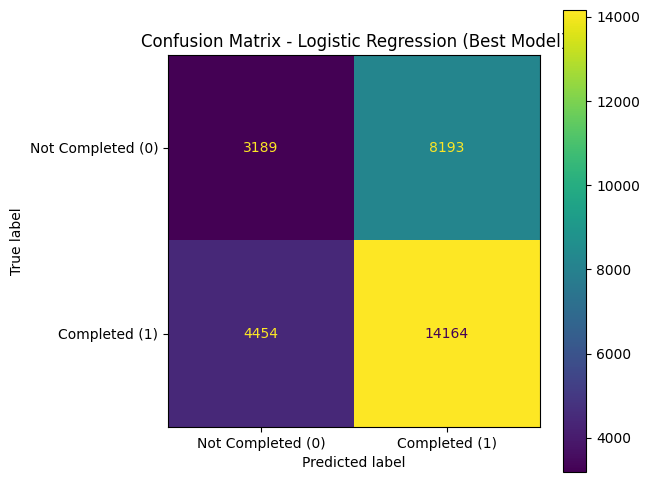

In [ ]:
cm = confusion_matrix(y_test, lr_best_estimator_predictions)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=['Not Completed (0)', 'Completed (1)']
)

fig, ax = plt.subplots(figsize=(6, 6))
disp.plot(ax=ax, values_format='d')
plt.title('Confusion Matrix - Logistic Regression (Best Model)')
plt.show()

In [ ]:
print(classification_report(y_test, lr_best_estimator_predictions))

              precision    recall  f1-score   support

           0       0.42      0.28      0.34     11382
           1       0.63      0.76      0.69     18618

    accuracy                           0.58     30000
   macro avg       0.53      0.52      0.51     30000
weighted avg       0.55      0.58      0.56     30000



In [ ]:
lr_y_proba = lr_best_estimator.predict_proba(X_test_cleaned)[:, 1]

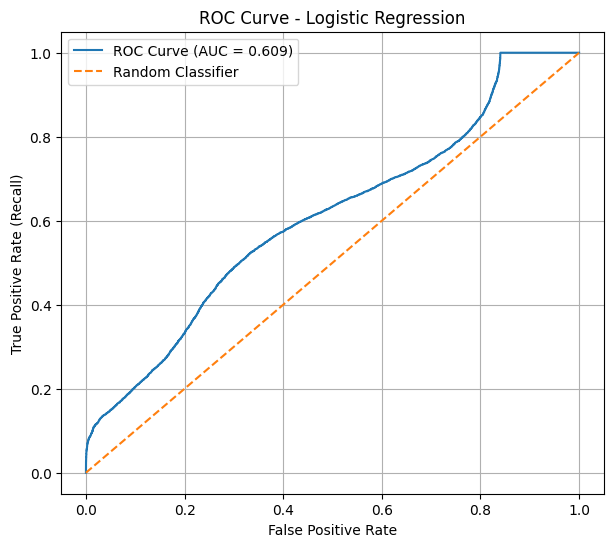

In [ ]:
fpr, tpr, thresholds = roc_curve(y_test, lr_y_proba)
roc_auc = roc_auc_score(y_test, lr_y_proba)

plt.figure(figsize=(7, 6))
plt.plot(fpr, tpr, label=f'ROC Curve (AUC = {roc_auc:.3f})')
plt.plot([0, 1], [0, 1], linestyle='--', label='Random Classifier')

plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate (Recall)')
plt.title('ROC Curve - Logistic Regression')
plt.legend()
plt.grid(True)

In [ ]:
# False Positive: predicted Completed, but the ride was not completed -> weight 5
# False Negative: predicted Not completed, but the ride completed  -> weight 1
COST_FP = 5
COST_FN = 1

def total_business_cost(y_true, y_pred):
    tn, fp, fn, tp = confusion_matrix(y_true, y_pred).ravel()
    return COST_FP * fp + COST_FN * fn

In [ ]:
# choose the threshold on a validation
val_cut = int(0.8 * len(X_train_cleaned))
lr_val_model = clone(lr_best_estimator).fit(X_train_cleaned.iloc[:val_cut], y_train.iloc[:val_cut])
lr_val_proba = lr_val_model.predict_proba(X_train_cleaned.iloc[val_cut:])[:, 1]

thresholds = np.arange(0.1, 0.9, 0.01)
costs = []

for t in thresholds:
    y_pred_t = (lr_val_proba >= t).astype(int)
    cost = total_business_cost(y_train.iloc[val_cut:], y_pred_t)
    costs.append(cost)

optimal_threshold = thresholds[np.argmin(costs)]
lr_test_cost = total_business_cost(y_test, (lr_y_proba >= optimal_threshold).astype(int))

print('Optimal threshold (chosen on validation):', round(optimal_threshold, 3))
print('Minimum validation business cost:', min(costs))
print('Test business cost at this threshold:', lr_test_cost)

Optimal threshold (chosen on validation): 0.64
Minimum validation business cost: 13998
Test business cost at this threshold: 17476


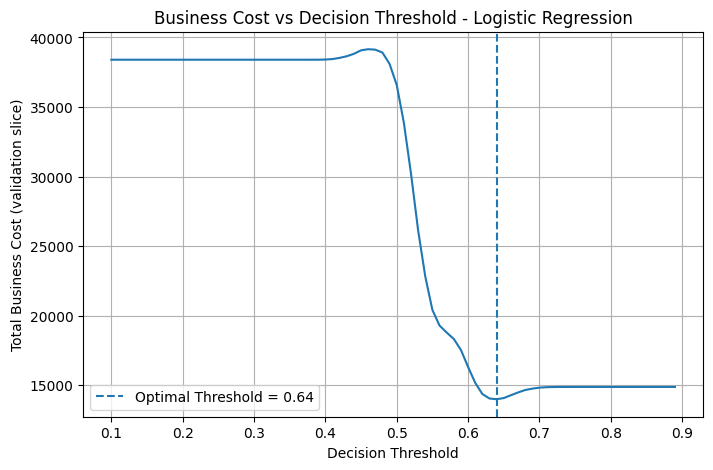

In [ ]:
plt.figure(figsize=(8, 5))

plt.plot(thresholds, costs)
plt.axvline(
    optimal_threshold,
    linestyle='--',
    label=f'Optimal Threshold = {optimal_threshold:.2f}'
)

plt.xlabel('Decision Threshold')
plt.ylabel('Total Business Cost (validation slice)')
plt.title('Business Cost vs Decision Threshold - Logistic Regression')
plt.legend()
plt.grid(True)

plt.show()


In [ ]:
lr_y_pred_optimal = (lr_y_proba >= optimal_threshold).astype(int)

print(classification_report(y_test, lr_y_pred_optimal))



              precision    recall  f1-score   support

           0       0.40      0.99      0.57     11382
           1       0.95      0.09      0.16     18618

    accuracy                           0.43     30000
   macro avg       0.67      0.54      0.36     30000
weighted avg       0.74      0.43      0.31     30000



# Random Forest

In [ ]:
rf_pipeline = Pipeline([
    ('smote', SMOTE(random_state=42)),
    ('rf', RandomForestClassifier(class_weight='balanced', random_state = 42))
])

rf_pipeline.fit(X_train_cleaned, y_train)

Pipeline(steps=[('smote', SMOTE(random_state=42)),
                ('rf',
                 RandomForestClassifier(class_weight='balanced',
                                        random_state=42))])

In [ ]:
rf_predictions = rf_pipeline.predict(X_test_cleaned)

print(f'Accuracy Score: {round(accuracy_score(y_test, rf_predictions), 4)}')
print(f'Precision Score: {round(precision_score(y_test, rf_predictions), 4)}')
print(f'Recall Score: {round(recall_score(y_test, rf_predictions), 4)}')
print(f'F1 Score: {round(f1_score(y_test, rf_predictions), 4)}')

Accuracy Score: 1.0
Precision Score: 1.0
Recall Score: 1.0
F1 Score: 1.0


In [ ]:
rf_param_grid = {
    'rf__n_estimators': [10, 20, 30],
    'rf__max_depth': [2, 5],
    'rf__min_samples_split': [2, 5],
    'rf__min_samples_leaf': [1, 2, 5],
}

rf_random_cv = RandomizedSearchCV(
    estimator=rf_pipeline,
    param_distributions=rf_param_grid,
    scoring='f1',
    cv=TimeSeriesSplit(n_splits=3),
    random_state=42,
    n_jobs=-1,
    n_iter=3,
    verbose = 2
)

rf_random_cv.fit(X_train_cleaned, y_train)

print("Best params:", rf_random_cv.best_params_)
print("Best F1:", rf_random_cv.best_score_)

Fitting 3 folds for each of 3 candidates, totalling 9 fits
Best params: {'rf__n_estimators': 20, 'rf__min_samples_split': 2, 'rf__min_samples_leaf': 5, 'rf__max_depth': 2}
Best F1: 0.9539783040877362


In [ ]:
rf_best_estimator = rf_random_cv.best_estimator_
rf_best_estimator_predictions = rf_best_estimator.predict(X_test_cleaned)

print(f'Accuracy Score: {round(accuracy_score(y_test, rf_best_estimator_predictions), 4)}')
print(f'Precision Score: {round(precision_score(y_test, rf_best_estimator_predictions), 4)}')
print(f'Recall Score: {round(recall_score(y_test, rf_best_estimator_predictions), 4)}')
print(f'F1 Score: {round(f1_score(y_test, rf_best_estimator_predictions), 4)}')


Accuracy Score: 0.9255
Precision Score: 0.9475
Recall Score: 0.9316
F1 Score: 0.9395


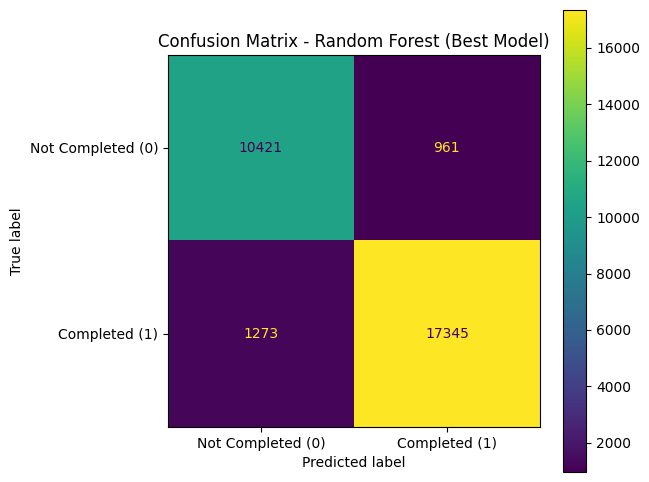

In [ ]:
cm = confusion_matrix(y_test, rf_best_estimator_predictions)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=['Not Completed (0)', 'Completed (1)']
)

fig, ax = plt.subplots(figsize=(6, 6))
disp.plot(ax=ax, values_format='d')
plt.title('Confusion Matrix - Random Forest (Best Model)')
plt.show()

In [ ]:
print(classification_report(y_test, rf_best_estimator_predictions))

              precision    recall  f1-score   support

           0       0.89      0.92      0.90     11382
           1       0.95      0.93      0.94     18618

    accuracy                           0.93     30000
   macro avg       0.92      0.92      0.92     30000
weighted avg       0.93      0.93      0.93     30000



In [ ]:
rf_y_proba = rf_best_estimator.predict_proba(X_test_cleaned)[:, 1]

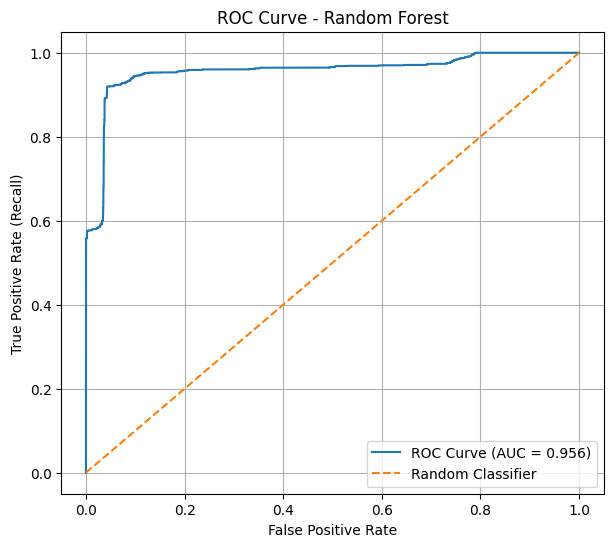

In [ ]:
fpr, tpr, thresholds = roc_curve(y_test, rf_y_proba)
roc_auc = roc_auc_score(y_test, rf_y_proba)

plt.figure(figsize=(7, 6))
plt.plot(fpr, tpr, label=f'ROC Curve (AUC = {roc_auc:.3f})')
plt.plot([0, 1], [0, 1], linestyle='--', label='Random Classifier')

plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate (Recall)')
plt.title('ROC Curve - Random Forest')
plt.legend()
plt.grid(True)

In [ ]:
# same relative cost weights as above (FP = 5, FN = 1)
COST_FP = 5
COST_FN = 1

def total_business_cost(y_true, y_pred):
    tn, fp, fn, tp = confusion_matrix(y_true, y_pred).ravel()
    return COST_FP * fp + COST_FN * fn


# choose the threshold on a validation slice (last 20% of the training period), not on the test set
val_cut = int(0.8 * len(X_train_cleaned))
rf_val_model = clone(rf_best_estimator).fit(X_train_cleaned.iloc[:val_cut], y_train.iloc[:val_cut])
rf_val_proba = rf_val_model.predict_proba(X_train_cleaned.iloc[val_cut:])[:, 1]

thresholds = np.arange(0.1, 0.9, 0.01)
costs = []

for t in thresholds:
    y_pred_t = (rf_val_proba >= t).astype(int)
    cost = total_business_cost(y_train.iloc[val_cut:], y_pred_t)
    costs.append(cost)

optimal_threshold = thresholds[np.argmin(costs)]
rf_test_cost = total_business_cost(y_test, (rf_y_proba >= optimal_threshold).astype(int))

print('Optimal threshold (chosen on validation):', round(optimal_threshold, 3))
print('Minimum validation business cost:', min(costs))
print('Test business cost at this threshold:', rf_test_cost)

Optimal threshold (chosen on validation): 0.51
Minimum validation business cost: 3341
Test business cost at this threshold: 4481


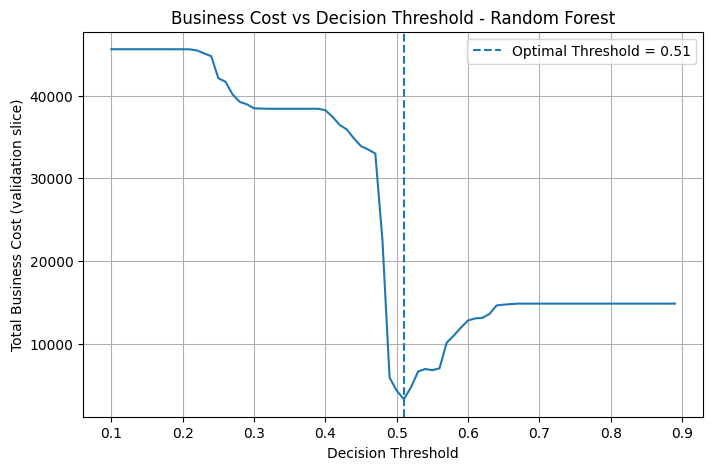

In [ ]:
plt.figure(figsize=(8, 5))

plt.plot(thresholds, costs)
plt.axvline(
    optimal_threshold,
    linestyle='--',
    label=f'Optimal Threshold = {optimal_threshold:.2f}'
)

plt.xlabel('Decision Threshold')
plt.ylabel('Total Business Cost (validation slice)')
plt.title('Business Cost vs Decision Threshold - Random Forest')
plt.legend()
plt.grid(True)

plt.show()


In [ ]:
rf_y_pred_optimal = (rf_y_proba >= optimal_threshold).astype(int)

print(classification_report(y_test, rf_y_pred_optimal))

              precision    recall  f1-score   support

           0       0.88      0.95      0.91     11382
           1       0.97      0.92      0.94     18618

    accuracy                           0.93     30000
   macro avg       0.92      0.93      0.93     30000
weighted avg       0.93      0.93      0.93     30000



# LightGBM

In [ ]:
IGNORED_COLS = ['Incomplete Rides']
lgbm_feature_contri = [0.0 if c in IGNORED_COLS else 1.0 for c in X_train_cleaned.columns]

lgbm_pipeline = Pipeline([
    ('smote', SMOTE(random_state=42)),
    ('lgbm', LGBMClassifier(class_weight='balanced', random_state = 42, feature_contri=lgbm_feature_contri))
])

lgbm_pipeline.fit(X_train_cleaned, y_train)

[LightGBM] [Warning] Found whitespace in feature_names, replace with underlines
[LightGBM] [Info] Number of positive: 74382, number of negative: 74382
[LightGBM] [Info] Auto-choosing row-wise multi-threading, the overhead of testing was 0.047151 seconds.
You can set `force_row_wise=true` to remove the overhead.
And if memory is not enough, you can set `force_col_wise=true`.
[LightGBM] [Info] Total Bins 4219
[LightGBM] [Info] Number of data points in the train set: 148764, number of used features: 24
[LightGBM] [Info] [binary:BoostFromScore]: pavg=0.500000 -> initscore=0.000000


Pipeline(steps=[('smote', SMOTE(random_state=42)),
                ('lgbm',
                 LGBMClassifier(class_weight='balanced',
                                feature_contri=[1.0, 1.0, 0.0, 1.0, 1.0, 1.0,
                                                1.0, 1.0, 1.0, 1.0, 1.0, 1.0,
                                                1.0, 1.0, 1.0, 1.0, 1.0, 1.0,
                                                1.0, 1.0, 1.0, 1.0, 1.0, 1.0],
                                random_state=42))])

In [ ]:
lgbm_predictions = lgbm_pipeline.predict(X_test_cleaned)

print(f'Accuracy Score: {round(accuracy_score(y_test, lgbm_predictions), 4)}')
print(f'Precision Score: {round(precision_score(y_test, lgbm_predictions), 4)}')
print(f'Recall Score: {round(recall_score(y_test, lgbm_predictions), 4)}')
print(f'F1 Score: {round(f1_score(y_test, lgbm_predictions), 4)}')

Accuracy Score: 0.9496
Precision Score: 0.931
Recall Score: 0.9924
F1 Score: 0.9607


In [ ]:
lgbm_param_grid = {
    'lgbm__n_estimators': [25, 50, 75],
    'lgbm__learning_rate': [0.01, 0.05, 0.1],
    'lgbm__max_depth': [5, 7],
    'lgbm__num_leaves': [15, 31, 63]
}

lgbm_random_cv = RandomizedSearchCV(
    estimator=lgbm_pipeline,
    param_distributions=lgbm_param_grid,
    scoring='f1',
    cv=TimeSeriesSplit(n_splits=3),
    random_state=42,
    n_jobs=-1,
    n_iter=3,
    verbose = 2
)

lgbm_random_cv.fit(X_train_cleaned, y_train)

print("Best params:", lgbm_random_cv.best_params_)
print("Best F1:", lgbm_random_cv.best_score_)

Fitting 3 folds for each of 3 candidates, totalling 9 fits
[LightGBM] [Warning] Found whitespace in feature_names, replace with underlines
[LightGBM] [Info] Number of positive: 74382, number of negative: 74382
[LightGBM] [Info] Auto-choosing row-wise multi-threading, the overhead of testing was 0.029548 seconds.
You can set `force_row_wise=true` to remove the overhead.
And if memory is not enough, you can set `force_col_wise=true`.
[LightGBM] [Info] Total Bins 4219
[LightGBM] [Info] Number of data points in the train set: 148764, number of used features: 24
[LightGBM] [Info] [binary:BoostFromScore]: pavg=0.500000 -> initscore=0.000000
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain

In [ ]:
lgbm_best_estimator = lgbm_random_cv.best_estimator_
lgbm_best_estimator_predictions = lgbm_best_estimator.predict(X_test_cleaned)

print(f'Accuracy Score: {round(accuracy_score(y_test, lgbm_best_estimator_predictions), 4)}')
print(f'Precision Score: {round(precision_score(y_test, lgbm_best_estimator_predictions), 4)}')
print(f'Recall Score: {round(recall_score(y_test, lgbm_best_estimator_predictions), 4)}')
print(f'F1 Score: {round(f1_score(y_test, lgbm_best_estimator_predictions), 4)}')


Accuracy Score: 0.9524
Precision Score: 0.9299
Recall Score: 0.9986
F1 Score: 0.963


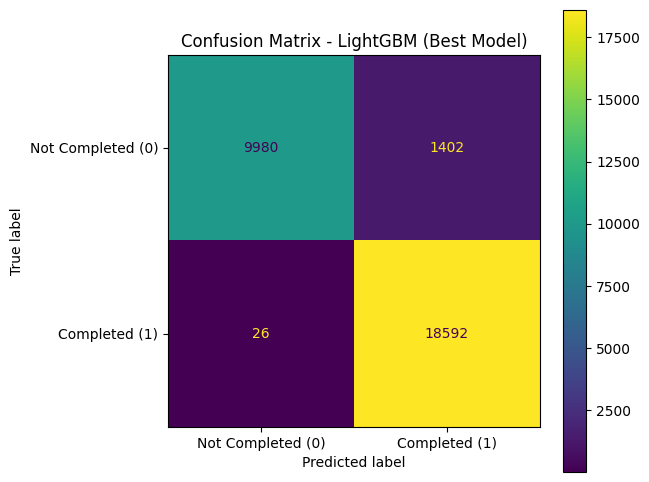

In [ ]:
cm = confusion_matrix(y_test, lgbm_best_estimator_predictions)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=['Not Completed (0)', 'Completed (1)']
)

fig, ax = plt.subplots(figsize=(6, 6))
disp.plot(ax=ax, values_format='d')
plt.title('Confusion Matrix - LightGBM (Best Model)')
plt.show()

In [ ]:
print(classification_report(y_test, lgbm_best_estimator_predictions))

              precision    recall  f1-score   support

           0       1.00      0.88      0.93     11382
           1       0.93      1.00      0.96     18618

    accuracy                           0.95     30000
   macro avg       0.96      0.94      0.95     30000
weighted avg       0.96      0.95      0.95     30000



In [ ]:
lgbm_y_proba = lgbm_best_estimator.predict_proba(X_test_cleaned)[:, 1]

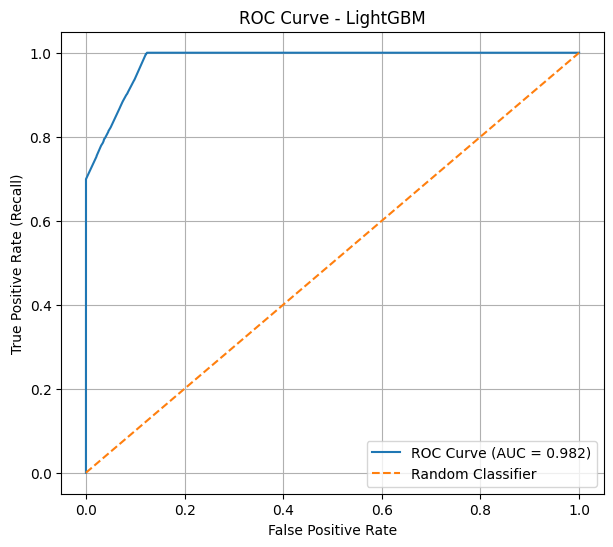

In [ ]:
fpr, tpr, thresholds = roc_curve(y_test, lgbm_y_proba)
roc_auc = roc_auc_score(y_test, lgbm_y_proba)

plt.figure(figsize=(7, 6))
plt.plot(fpr, tpr, label=f'ROC Curve (AUC = {roc_auc:.3f})')
plt.plot([0, 1], [0, 1], linestyle='--', label='Random Classifier')

plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate (Recall)')
plt.title('ROC Curve - LightGBM')
plt.legend()
plt.grid(True)

In [ ]:
COST_FP = 5
COST_FN = 1

def total_business_cost(y_true, y_pred):
    tn, fp, fn, tp = confusion_matrix(y_true, y_pred).ravel()
    return COST_FP * fp + COST_FN * fn


val_cut = int(0.8 * len(X_train_cleaned))
lgbm_val_model = clone(lgbm_best_estimator).fit(X_train_cleaned.iloc[:val_cut], y_train.iloc[:val_cut])
lgbm_val_proba = lgbm_val_model.predict_proba(X_train_cleaned.iloc[val_cut:])[:, 1]

thresholds = np.arange(0.1, 0.9, 0.01)
costs = []

for t in thresholds:
    y_pred_t = (lgbm_val_proba >= t).astype(int)
    cost = total_business_cost(y_train.iloc[val_cut:], y_pred_t)
    costs.append(cost)

optimal_threshold = thresholds[np.argmin(costs)]
lgbm_test_cost = total_business_cost(y_test, (lgbm_y_proba >= optimal_threshold).astype(int))

print('Optimal threshold (chosen on validation):', round(optimal_threshold, 3))
print('Minimum validation business cost:', min(costs))
print('Test business cost at this threshold:', lgbm_test_cost)

[LightGBM] [Warning] Found whitespace in feature_names, replace with underlines
[LightGBM] [Info] Number of positive: 59500, number of negative: 59500
[LightGBM] [Info] Auto-choosing row-wise multi-threading, the overhead of testing was 0.023983 seconds.
You can set `force_row_wise=true` to remove the overhead.
And if memory is not enough, you can set `force_col_wise=true`.
[LightGBM] [Info] Total Bins 4178
[LightGBM] [Info] Number of data points in the train set: 119000, number of used features: 24
[LightGBM] [Info] [binary:BoostFromScore]: pavg=0.500000 -> initscore=0.000000
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits wi

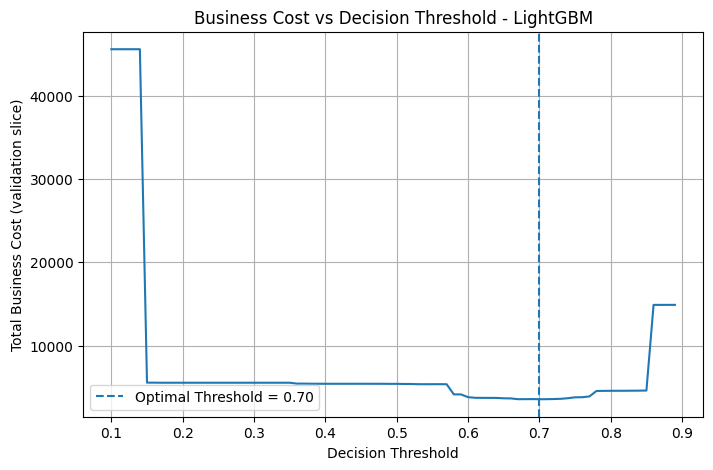

In [ ]:
plt.figure(figsize=(8, 5))

plt.plot(thresholds, costs)
plt.axvline(
    optimal_threshold,
    linestyle='--',
    label=f'Optimal Threshold = {optimal_threshold:.2f}'
)

plt.xlabel('Decision Threshold')
plt.ylabel('Total Business Cost (validation slice)')
plt.title('Business Cost vs Decision Threshold - LightGBM')
plt.legend()
plt.grid(True)

plt.show()


In [ ]:
lgbm_y_pred_optimal = (lgbm_y_proba >= optimal_threshold).astype(int)

print(classification_report(y_test, lgbm_y_pred_optimal))

              precision    recall  f1-score   support

           0       0.74      0.96      0.84     11382
           1       0.97      0.80      0.87     18618

    accuracy                           0.86     30000
   macro avg       0.86      0.88      0.86     30000
weighted avg       0.88      0.86      0.86     30000



# Summary of Models Performance

In [ ]:
summary_preds = {
    'Logistic Regression': (lr_best_estimator_predictions, lr_test_cost),
    'Random Forest': (rf_best_estimator_predictions, rf_test_cost),
    'LightGBM': (lgbm_best_estimator_predictions, lgbm_test_cost),
}

summary_df = pd.DataFrame({
    'Models': list(summary_preds.keys()),
    'Accuracy': [round(accuracy_score(y_test, p), 4) for p, _ in summary_preds.values()],
    'Precision': [round(precision_score(y_test, p), 4) for p, _ in summary_preds.values()],
    'Recall': [round(recall_score(y_test, p), 4) for p, _ in summary_preds.values()],
    'F1 Score': [round(f1_score(y_test, p), 4) for p, _ in summary_preds.values()],
    'False Positives': [confusion_matrix(y_test, p)[0][1] for p, _ in summary_preds.values()],
    'False Negatives': [confusion_matrix(y_test, p)[1][0] for p, _ in summary_preds.values()],
    'Business Cost at Validation-Chosen Threshold (weighted)': [cost for _, cost in summary_preds.values()],
})

summary_df

,Models,Accuracy,Precision,Recall,F1 Score,False Positives,False Negatives,Business Cost at Validation-Chosen Threshold (weighted)
0,Logistic Regression,0.5784,0.6335,0.7608,0.6913,8193,4454,17476
1,Random Forest,0.9255,0.9475,0.9316,0.9395,961,1273,4481
2,LightGBM,0.9524,0.9299,0.9986,0.9630,1402,26,5956


# Choosing the Model

LightGBM has been selected as the final model because it has the best overall classification performance on the test set at the default 0.5 threshold: the highest accuracy (0.9524), recall (0.9986) and F1-score (0.9630). It makes very few false negatives (26), but more false positives (1,402) than Random Forest (961).

The choice involves a trade-off. At each model's validation-chosen threshold, Random Forest has the lowest business cost (4,481 weighted units) against 5,956 for LightGBM and 17,476 for Logistic Regression. Because false positives are weighted five times higher than false negatives, Random Forest would be the better pick if business cost is the deciding metric.


# E1. Error Analysis

In [ ]:
# Error analysis for the selected LightGBM model.

lgbm_predictions_default = lgbm_best_estimator.predict(X_test_cleaned)
lgbm_y_proba = lgbm_best_estimator.predict_proba(X_test_cleaned)[:, 1]
lgbm_y_pred_optimal = (lgbm_y_proba >= optimal_threshold).astype(int)

print(f"Threshold chosen by cost minimisation on validation: {optimal_threshold:.2f}")

cm_default = confusion_matrix(y_test, lgbm_predictions_default)
cm_optimal = confusion_matrix(y_test, lgbm_y_pred_optimal)

tn_default, fp_default, fn_default, tp_default = cm_default[0][0], cm_default[0][1], cm_default[1][0], cm_default[1][1]
tn_optimal, fp_optimal, fn_optimal, tp_optimal = cm_optimal[0][0], cm_optimal[0][1], cm_optimal[1][0], cm_optimal[1][1]

precision_default = precision_score(y_test, lgbm_predictions_default)
recall_default = recall_score(y_test, lgbm_predictions_default)
precision_optimal = precision_score(y_test, lgbm_y_pred_optimal)
recall_optimal = recall_score(y_test, lgbm_y_pred_optimal)

print("\n--- Threshold Comparison (test set) ---")
print(f"{'Metric':<25} {'Default (0.5)':<15} {'Chosen ({:.2f})':<15} {'Change':<10}".format(optimal_threshold))
print("-"*65)
print(f"{'False Positives':<25} {fp_default:<15,} {fp_optimal:<15,} {fp_optimal-fp_default:<10,}")
print(f"{'False Negatives':<25} {fn_default:<15,} {fn_optimal:<15,} {fn_optimal-fn_default:<10,}")
print(f"{'True Positives':<25} {tp_default:<15,} {tp_optimal:<15,} {tp_optimal-tp_default:<10,}")
print(f"{'True Negatives':<25} {tn_default:<15,} {tn_optimal:<15,} {tn_optimal-tn_default:<10,}")
print(f"{'Precision':<25} {precision_default:<15.3f} {precision_optimal:<15.3f} {precision_optimal-precision_default:<10.3f}")
print(f"{'Recall':<25} {recall_default:<15.3f} {recall_optimal:<15.3f} {recall_optimal-recall_default:<10.3f}")

cost_default = total_business_cost(y_test, lgbm_predictions_default)
cost_optimal = total_business_cost(y_test, lgbm_y_pred_optimal)
print(f"{'Business cost (weighted)':<25} {cost_default:<15,} {cost_optimal:<15,} {cost_optimal-cost_default:<10,}")

print("\n--- Model Confidence Analysis ---")
print(f"Min probability: {lgbm_y_proba.min():.4f}")
print(f"Max probability: {lgbm_y_proba.max():.4f}")
print(f"Mean probability: {lgbm_y_proba.mean():.4f}")
print(f"Median probability: {np.median(lgbm_y_proba):.4f}")
print(f"Distinct probability values: {np.unique(lgbm_y_proba.round(4)).size:,}")

print("\nProbability distribution:")
print(f"Predictions < 0.10: {(lgbm_y_proba < 0.10).sum():,}")
print(f"Predictions 0.10-0.50: {((lgbm_y_proba >= 0.10) & (lgbm_y_proba < 0.50)).sum():,}")
print(f"Predictions >= 0.50: {(lgbm_y_proba >= 0.50).sum():,}")

print("\n" + "-"*50)
print("KEY FINDING")
print("-"*50)
if cost_optimal < cost_default:
    print(f"Moving the threshold from 0.5 to {optimal_threshold:.2f} lowers the test business cost")
    print(f"from {cost_default:,} to {cost_optimal:,}, trading {fn_optimal-fn_default:+,} false negatives")
    print(f"for {fp_optimal-fp_default:+,} false positives.")
elif cost_optimal == cost_default:
    print("The chosen threshold gives the same test business cost as 0.5.")
else:
    print(f"The validation-chosen threshold ({optimal_threshold:.2f}) does NOT lower the test business cost")
    print(f"({cost_optimal:,} vs {cost_default:,} at 0.5); it did not carry over from validation to test.")

print("\n" + "-"*50)
print("ERROR ANALYSIS (default 0.5 threshold)")
print("-"*50)

total_test = len(y_test)
error_rate = (fp_default + fn_default) / total_test

print(f"\nTotal predictions: {total_test:,}")
print(f"Correct predictions: {tp_default + tn_default:,}")
print(f"Total errors: {fp_default + fn_default:,}")
print(f"Error rate: {error_rate:.2%}")

print(f"\n--- False Positives: {fp_default:,} cases ({(fp_default/total_test)*100:.2f}% of bookings) ---")
print("Definition: model predicts 'Completed' but the booking was not completed")
print("\nBusiness Impact:")
print("• Driver is dispatched to the pickup location")
print("• Booking is not completed → driver loses time and fuel")
print("• No revenue for the trip, only cost (fuel, time, opportunity cost)")
print("• Repeated cases frustrate drivers → higher churn risk")
print("\nCost Assessment: HIGH (weighted 5x in the business cost)")
print("• Drivers are the constrained resource")
print("• Each FP damages driver trust and platform reliability")

print(f"\n--- False Negatives: {fn_default:,} cases ({(fn_default/total_test)*100:.2f}% of bookings) ---")
print("Definition: model predicts 'Not completed' but the ride actually completes")
print("\nBusiness Impact:")
print("• System flags the booking as high-risk")
print("• May trigger unnecessary alerts or interventions")
print("• Ride completes and revenue is generated normally")
print("\nCost Assessment: LOW (weighted 1x in the business cost)")
print("• Operational inefficiency only (extra monitoring)")
print("• Customer is unaware of internal flagging")

print("\n" + "-"*50)
print("RECOMMENDATION")
print("-"*50)
better = optimal_threshold if cost_optimal < cost_default else 0.5
print(f"""
1. USE THRESHOLD {better:.2f}
   - Lower test business cost of the two thresholds compared above
   - At 0.5: precision {precision_default:.1%}, recall {recall_default:.1%}
   - At {optimal_threshold:.2f}: precision {precision_optimal:.1%}, recall {recall_optimal:.1%}

2. REVIEW THE {fp_default:,} FALSE POSITIVE CASES (at 0.5)
   - Look for patterns: customer segments, time periods, locations
   - Root cause: why are these bookings predicted to complete?

3. MONITOR FP RATE OVER TIME
   - Current FP rate: {(fp_default/total_test)*100:.2f}% of bookings ({fp_default/(fp_default+tn_default):.2%} of non-completed bookings)
   - Track weekly to detect model drift and retrain if it rises

4. ACCEPT A SMALL NUMBER OF FALSE NEGATIVES ({fn_default:,} at 0.5)
   - Rides still complete, so business impact is small
   - Focus effort on reducing FPs rather than FNs
""")


Threshold chosen by cost minimisation on validation: 0.70

--- Threshold Comparison (test set) ---
Metric                    Default (0.5)   Chosen (0.70) Change    
-----------------------------------------------------------------
False Positives           1,402           429             -973      
False Negatives           26              3,811           3,785     
True Positives            18,592          14,807          -3,785    
True Negatives            9,980           10,953          973       
Precision                 0.930           0.972           0.042     
Recall                    0.999           0.795           -0.203    
Business cost (weighted)  7,036           5,956           -1,080    

--- Model Confidence Analysis ---
Min probability: 0.1412
Max probability: 0.8600
Mean probability: 0.5754
Median probability: 0.7345
Distinct probability values: 269

Probability distribution:
Predictions < 0.10: 0
Predictions 0.10-0.50: 10,006
Predictions >= 0.50: 19,994

---------

# E2. High-Risk Segments



In [ ]:
# High-risk segments in the test set.

print("\n" + "-"*70)
print("SUMMARY OF HIGH-RISK SEGMENTS")
print("-"*70)

# Total cancellations from y_test
total_cancellations = (y_test == 0).sum()
total_completions = (y_test == 1).sum()
total_test = len(y_test)

# Segment 1: Repeat Cancellers
segment1_mask = X_test_cleaned['Customer_Cancellation_Rate'] > 0.40
segment1_total = segment1_mask.sum()
segment1_cancellations = ((y_test.values == 0) & segment1_mask.values).sum()

# Segment 2: Peak Hours
peak_cols = [col for col in X_test_cleaned.columns if 'Morning Peak' in col or 'Evening Rush' in col]
segment2_mask = X_test_cleaned[peak_cols].sum(axis=1) > 0
segment2_total = segment2_mask.sum()
segment2_cancellations = ((y_test.values == 0) & segment2_mask.values).sum()

# Segment 3: High-Risk Geographic Zones
pickup_threshold = X_test_cleaned['Pickup Location Encoded'].quantile(0.25)
segment3_mask = X_test_cleaned['Pickup Location Encoded'] < pickup_threshold
segment3_total = segment3_mask.sum()
segment3_cancellations = ((y_test.values == 0) & segment3_mask.values).sum()

print(f"\nTotal test bookings: {total_test:,}")
print(f"Total non-completed: {total_cancellations:,} ({(total_cancellations/total_test)*100:.1f}%)")
print(f"Total completions: {total_completions:,} ({(total_completions/total_test)*100:.1f}%)")

print(f"\n{'Segment':<45} {'Bookings':<12} {'Cancels':<12} {'% of All Cancels':<12}")
print("-"*85)
print(f"{'1. Repeat Cancellers (>40% prior rate)':<45} {segment1_total:<12,} {segment1_cancellations:<12,} {(segment1_cancellations/total_cancellations)*100:<11.1f}%")
print(f"{'2. Peak Hours (6-10 AM, 4-8 PM)':<45} {segment2_total:<12,} {segment2_cancellations:<12,} {(segment2_cancellations/total_cancellations)*100:<11.1f}%")
print(f"{'3. Low-Completion Pickup Zones (Bottom 25%)':<45} {segment3_total:<12,} {segment3_cancellations:<12,} {(segment3_cancellations/total_cancellations)*100:<11.1f}%")

# Combined segments (accounting for overlap)
combined_mask = segment1_mask | segment2_mask | segment3_mask
combined_total = combined_mask.sum()
combined_cancellations = ((y_test.values == 0) & combined_mask.values).sum()

print(f"\n{'Combined (All 3 Segments)':<45} {combined_total:<12,} {combined_cancellations:<12,} {(combined_cancellations/total_cancellations)*100:<11.1f}%")

print(f"\n{'-'*70}")
print("CANCELLATION RATES BY SEGMENT")
print(f"{'-'*70}")
print(f"{'Segment':<45} {'Cancellation Rate':<15}")
print("-"*60)
print(f"{'Overall Platform':<45} {(total_cancellations/total_test)*100:<14.1f}%")
print(f"{'Segment 1 (Repeat Cancellers)':<45} {(segment1_cancellations/segment1_total)*100:<14.1f}%")
print(f"{'Segment 2 (Peak Hours)':<45} {(segment2_cancellations/segment2_total)*100:<14.1f}%")
print(f"{'Segment 3 (Low-Completion Zones)':<45} {(segment3_cancellations/segment3_total)*100:<14.1f}%")

print(f"\n{'-'*70}")
print("KEY INSIGHTS")
print(f"{'-'*70}")
print(f"• Segments cover {(combined_total/total_test)*100:.1f}% of all bookings")
print(f"• They contain {(combined_cancellations/total_cancellations)*100:.1f}% of non-completed bookings")
print(f"• Largest contributor: Segment {'1' if segment1_cancellations == max(segment1_cancellations, segment2_cancellations, segment3_cancellations) else '2' if segment2_cancellations == max(segment1_cancellations, segment2_cancellations, segment3_cancellations) else '3'}")
overall_rate_test = total_cancellations / total_test
for name, c, t in [('Segment 1', segment1_cancellations, segment1_total),
                   ('Segment 2', segment2_cancellations, segment2_total),
                   ('Segment 3', segment3_cancellations, segment3_total)]:
    lift = (c / t) / overall_rate_test
    verdict = 'higher than' if lift > 1.05 else 'lower than' if lift < 0.95 else 'about the same as'
    print(f"• {name}: cancellation rate is {verdict} the platform average (lift {lift:.2f}x)")
print("• A segment is only worth targeting if its rate is clearly above the average, not just because it is large")


----------------------------------------------------------------------
SUMMARY OF HIGH-RISK SEGMENTS
----------------------------------------------------------------------

Total test bookings: 30,000
Total non-completed: 11,382 (37.9%)
Total completions: 18,618 (62.1%)

Segment                                       Bookings     Cancels      % of All Cancels
-------------------------------------------------------------------------------------
1. Repeat Cancellers (>40% prior rate)        162          59           0.5        %
2. Peak Hours (6-10 AM, 4-8 PM)               13,709       5,240        46.0       %
3. Low-Completion Pickup Zones (Bottom 25%)   7,482        2,815        24.7       %

Combined (All 3 Segments)                     17,855       6,789        59.6       %

----------------------------------------------------------------------
CANCELLATION RATES BY SEGMENT
----------------------------------------------------------------------
Segment                               

# E3. Executive Summary

In [ ]:
# Executive summary figures for the selected LightGBM model (default 0.5 threshold)
lgbm_cm = confusion_matrix(y_test, lgbm_best_estimator_predictions)
lgbm_tn, lgbm_fp, lgbm_fn, lgbm_tp = lgbm_cm.ravel()

lgbm_fpr = round(lgbm_fp / (lgbm_fp + lgbm_tn), 4)
lgbm_auc = roc_auc_score(y_test, lgbm_best_estimator.predict_proba(X_test_cleaned)[:, 1])
lgbm_f1 = f1_score(y_test, lgbm_best_estimator_predictions)

Markdown(f"""
The LightGBM model predicts ride completion on the held-out test period with an
AUC of {lgbm_auc:.3f}, an F1-score of {lgbm_f1:.3f} and a false positive rate of
$\\text{{FPR}} = {lgbm_fpr:.4f}$ (share of non-completed bookings predicted to complete).
By using temporal, location and customer-history features, the model provides an early
warning signal for high-risk bookings. These scores may be inflated by remaining leakage
(see the model-choice notes) and should be re-checked before deployment.
""")



The LightGBM model predicts ride completion on the held-out test period with an
AUC of 0.982, an F1-score of 0.963 and a false positive rate of
$\text{FPR} = 0.1232$ (share of non-completed bookings predicted to complete).
By using temporal, location and customer-history features, the model provides an early
warning signal for high-risk bookings. These scores may be inflated by remaining leakage
(see the model-choice notes) and should be re-checked before deployment.


# E4. Ethical / Operational Risks

In [ ]:
# RISK 1: API Latency (time for one single-booking prediction through the full pipeline)

print("\nRISK 1: API Latency (Operational)")
print("-"*50)

start = time.time()
prediction = lgbm_best_estimator.predict(X_test_cleaned.iloc[:1])
end = time.time()

latency_ms = (end - start) * 1000

print(f"Prediction latency: {latency_ms:.2f} ms")

print("\nRecommendations:")
print("• Use LightGBM (fast inference)")
print("• Deploy on optimized server")
print("• Cache customer features")


# RISK 2: Geographic Fairness
# Zones are grouped by their training completion rate (target encoding), not by income.
# FPR = share of non-completed bookings in a zone that the model predicts will complete.
print("\n\nRISK 2: Geographic Fairness (Ethical)")
print("-"*50)

lgbm_predictions = lgbm_best_estimator.predict(X_test_cleaned)

pickup_quartiles = pd.qcut(X_test_cleaned['Pickup Location Encoded'].values,
                           q=4, labels=['Worst Zones', 'Q2', 'Q3', 'Best Zones'])

worst_zones = pickup_quartiles == 'Worst Zones'
best_zones = pickup_quartiles == 'Best Zones'

y_test_array = y_test.values if hasattr(y_test, 'values') else y_test

cm_worst = confusion_matrix(y_test_array[worst_zones], lgbm_predictions[worst_zones])
fpr_worst = cm_worst[0][1] / (cm_worst[0][1] + cm_worst[0][0])

cm_best = confusion_matrix(y_test_array[best_zones], lgbm_predictions[best_zones])
fpr_best = cm_best[0][1] / (cm_best[0][1] + cm_best[0][0])

disparity = abs(fpr_worst - fpr_best)

print(f"FPR in worst zones (lowest completion rate): {fpr_worst:.2%}")
print(f"FPR in best zones (highest completion rate): {fpr_best:.2%}")
print(f"Disparity: {disparity:.2%}")

print("\nRecommendations:")
print("• Monitor FPR by zone monthly")
print("• Alert if disparity > 5%")
print("• Avoid penalizing customers simply for booking from low-completion zones")



RISK 1: API Latency (Operational)
--------------------------------------------------
Prediction latency: 4.20 ms

Recommendations:
• Use LightGBM (fast inference)
• Deploy on optimized server
• Cache customer features


RISK 2: Geographic Fairness (Ethical)
--------------------------------------------------
FPR in worst zones (lowest completion rate): 12.46%
FPR in best zones (highest completion rate): 12.70%
Disparity: 0.25%

Recommendations:
• Monitor FPR by zone monthly
• Alert if disparity > 5%
• Avoid penalizing customers simply for booking from low-completion zones
